![Banner](../images/09_03_banner_rs_rader.png)


# SAR Fundamentals

Synthetic Aperture Radar (SAR) sends its own microwave pulses and records the echoes, so it images day and night and through clouds.

Twenty-four notebooks take a radar image from the echo to a map, in three mission blocks: Sentinel-1, RADARSAT, and NISAR.

- **SAR Fundamentals.** This notebook. How a SAR image is formed, how to read brightness, and the functions in `geolattice.rsense.sar`.
- **Sentinel-1 SAR.** The Copernicus C-band mission: satellites, modes, product levels, polarisations, and applications.
- **Sentinel-1 SAR Processing.** Choose a chain for the product and the question: GRD backscatter, a time series, SLC, coherence, deformation, or polarimetry.
- **Sentinel-1 GRD Processing.** Calibrate, filter, and terrain-correct the 13 January 2024 IW scene over Cox's Bazar and Teknaf to sigma0, beta0, and gamma0.
- **Sentinel-1 Multitemporal GRD Time Series: Deforestation around the Rohingya Camps (2017).** A 2017 stack over the Rohingya camps, co-registered and speckle-filtered, then used to map forest clearing.
- **Topographic InSAR: a DEM from a Sentinel-1 SLC Pair.** A DEM from one Sentinel-1 SLC pair, from pair selection through unwrapping and terrain correction.
- **Differential InSAR (DInSAR).** Ground displacement from two dates, applied to subsidence in Mexico City.
- **SBAS (Small Baseline Subset) InSAR.** A small-baseline network of 24 Sentinel-1 acquisitions over Mexico City in 2025, inverted to a displacement time series.
- **Persistent Scatterer InSAR (PS-InSAR).** Stable reflectors through the same Mexico City stack.
- **Dual-Pol Polarimetric Decomposition (SLC).** Entropy, anisotropy, and alpha from VV and VH on the Teknaf coast.
- **Interferometric Coherence of SLCs.** Pixel-by-pixel similarity of two SLC images, computed over Mexico City.
- **Sentinel-1 Based Indices.** RVI, the Radar Forest Degradation Index, and related dual-pol indices on the Cox's Bazar window.
- **RADARSAT Constellation Mission (RCM).** Canada's three-satellite C-band constellation: design, modes, products, and applications.
- **RADARSAT Constellation Mission (RCM) Processing.** Backscatter, compact-pol, and InSAR chains from the product to a map-ready layer.
- **RADARSAT GRD Data.** Noise removal, calibration to sigma-nought, multilooking, and speckle filtering of an RCM GRD scene.
- **RADARSAT Constellation Mission (RCM) InSAR Processing.** A two-pass interferogram on Stripmap SLC: coregistration, unwrapping, displacement, and geocoding.
- **RADARSAT Polarimetric SAR (PolSAR).** Quad-pol scattering: single bounce, volume, and double bounce from covariance and coherency matrices.
- **Compact-polarimetry (CP).** A circular transmit and two linear receives, simulated from a RADARSAT-2 quad-pol scene.
- **NISAR: NASA-ISRO Synthetic Aperture Radar.** The NASA-ISRO L-band and S-band mission, its products, and how processing differs from Sentinel-1.
- **NISAR Processing.** Read the HDF5 products and the steps that remain for Level-1 radar geometry and Level-2 geocoded grids.
- **NISAR RSLC: Range-Doppler Single Look Complex Processing.** Multilooked HH/HV quick looks from the range-Doppler SLC over coastal Bangladesh.
- **NISAR GSLC: Geocoded Single Look Complex Processing.** Geocoded amplitude, intensity, phase, and a dual-pol RGB for the same coast.
- **NISAR GCOV: Geocoded Polarimetric Covariance Processing.** HH and HV geocoded covariance terms for the coastal Bangladesh AOI.
- **NISAR GUNW: Geocoded Unwrapped Interferogram.** Unwrapped phase, coherence, and the ionosphere screen, masked and converted to displacement.


## Overview

A SAR image is not a photograph: it is formed in *slant range*, brightness reflects surface roughness, geometry and moisture rather than colour, and every pixel carries speckle. This notebook introduces the radar chapter (`09_03`): how SAR works, how to interpret brightness and geometry, what `geolattice.rsense.sar` provides, and hands-on examples with real and simulated Sentinel-1 data.


## Core concepts

### Learning objectives

1. Explain how an active microwave sensor forms a SAR image, and what slant range, azimuth, amplitude and phase mean.
2. Relate wavelength and polarisation to penetration, roughness and scattering mechanisms.
3. Recognise surface, volume and double-bounce scattering and their typical backscatter.
4. Explain side-looking geometry: incidence angle, foreshortening, layover and shadow.
5. Explain speckle statistically and quantify it with the equivalent number of looks (ENL).
6. Find the right function in `geolattice.rsense.sar` (`src/rsense/sar`) for a task.
7. Read real Sentinel-1 backscatter in linear and dB units, and interpret a simulated Sentinel-1 scene.

### Contents

1. What is SAR
2. How to read brightness
3. Types of radar images
4. Applications by sector
5. Key missions
6. How a radar image works
7. The basic principle: radar is an active sensor
8. How microwave energy interacts with Earth's surface
9. SAR image geometry: range, azimuth, and incidence angle
10. How synthetic aperture radar works
11. How a SAR image is organized
12. SAR brightness and backscatter
13. Wavelength and radar bands
14. Polarization
15. Typical SAR image processing workflow
16. Application: detecting floods with Sentinel-1
17. SAR versus optical imagery
18. Quick knowledge check
19. SAR in GeoLattice: `geolattice.rsense.sar`
20. Notebooks in this chapter
21. Data
22. Setup
23. Microwave bands, penetration and roughness
24. Imaging geometry
25. Scattering mechanisms and incidence angle
26. Speckle
27. Real Sentinel-1 backscatter
28. A simulated Sentinel-1 view of Long Valley
29. Sentinel-1 acquisition modes and products
30. Summary, exercises and references


## What is SAR

**RADAR** stands for **RA**dio **D**etection **A**nd **R**anging. A radar image is made by an **active** sensor. The sensor sends out microwave pulses, usually looking sideways from an aircraft or satellite, and records the energy that bounces back, called **backscatter**. Each pixel stores the strength (amplitude) of that echo. In complex data it also stores the **phase**, and the echo's timing fixes the pixel's position.

Optical images record reflected sunlight. Radar is different in a few ways:

- **Day and night, all weather.** Microwaves pass through cloud, smoke, haze, and light rain, and the sensor provides its own illumination.
- **It sees physical and electrical properties, not color.** Brightness depends on surface roughness, geometry, moisture (dielectric constant), and structure.
- **Wavelength sets how far the signal penetrates:**
  - X-band (~3 cm) mostly interacts with leaves and surface detail.
  - C-band (~5.6 cm) reaches into crop canopies.
  - L-band (~23 cm) and P-band (~70 cm) penetrate forest canopy and dry soil.
- **Polarization** describes the transmit and receive orientation (HH, VV, HV, VH). Each combination responds to different scattering mechanisms.


## How to read brightness

| Appearance | Scattering mechanism | Typical surface |
|---|---|---|
| Very dark | Specular (mirror-like) reflection away from sensor | Calm water, roads, airport runways |
| Medium, textured | Surface scattering | Bare or rough soil, grassland |
| Bright in cross-pol (HV/VH) | Volume scattering | Forest canopy, dense crops |
| Very bright | Double-bounce (corner reflector) | Buildings, flooded forest, ships |

Two other features are typical of radar images:

- **Speckle** is a granular "salt-and-pepper" noise that comes from coherent imaging.
- **Geometric distortions** affect steep terrain. These are foreshortening, layover, and radar shadow.


## Types of radar images

**1. Real Aperture Radar (RAR / SLAR)**
- This is early side-looking airborne radar.
- Resolution is limited by the physical length of the antenna, so it is coarse at long range.
- Today it is mainly of historical interest. It was used for regional mapping in cloudy tropics, such as Brazil's RADAM project.

**2. Synthetic Aperture Radar (SAR)**
- SAR uses the platform's motion and signal processing to simulate a very long antenna. This gives fine resolution regardless of altitude.
- Common products:
  - **SLC (Single Look Complex):** amplitude plus phase, in slant-range geometry. It is the input for interferometry and polarimetry.
  - **GRD (Ground Range Detected):** amplitude or intensity only, multilooked, and projected to ground range. This is the standard "radar picture," for example Sentinel-1 GRD.
- Imaging modes trade coverage against resolution:
  - **Spotlight:** finest detail, smallest area.
  - **Stripmap:** a balance of the two.
  - **ScanSAR / TOPS:** wide swath, coarser resolution.
- **Applications:** flood mapping, oil spill and ship detection, sea-ice monitoring, land cover classification, and deforestation alerts.

**3. Polarimetric SAR (PolSAR)**
- Images are acquired in single-, dual-, or quad (full) polarization.
- Quad-pol data can be split into scattering mechanisms using decompositions such as Pauli, Freeman-Durden, or H/A/α.
- **Applications:** crop type mapping and crop growth stage, forest biomass, wetland classification, soil moisture retrieval, and urban structure.

**4. Interferometric SAR (InSAR)**
- InSAR uses the phase difference between two SAR images of the same area taken from slightly different positions or at different times.
- Products:
  - **Interferogram:** colored fringes, where each fringe is one cycle of phase.
  - **Coherence image:** shows how stable the surface was between the two dates.
  - **DEM:** for example SRTM and TanDEM-X.
- **Differential InSAR (DInSAR)** and time-series methods (**PS-InSAR, SBAS**) measure ground motion at millimeter to centimeter scale.
- **Applications:**
  - Earthquake and volcano deformation.
  - Land subsidence from groundwater pumping or mining.
  - Landslides.
  - Stability of infrastructure such as dams, bridges, and railways.
  - Glacier flow.
  - Coherence-based damage and change mapping.

**5. Polarimetric Interferometric SAR (PolInSAR) and Tomographic SAR (TomoSAR)**
- PolInSAR combines polarimetry and interferometry. TomoSAR uses many passes to resolve vertical structure.
- **Applications:** forest canopy height, 3D forest structure, biomass, and 3D urban reconstruction. These are mainly done with P- and L-band, as in the ESA BIOMASS mission.

**6. Multi-temporal SAR stacks**
- A dense time series is built from repeat passes. Sentinel-1, for example, revisits every 6 to 12 days.
- **Applications:**
  - Crop phenology and planting or harvest detection, such as rice mapping in monsoon Asia.
  - Change detection.
  - Flood progression.
  - Near-real-time disaster response.

**7. Other radar imaging systems**
- **Weather (Doppler) radar** is ground-based (e.g., NEXRAD). Its reflectivity and velocity images show rainfall intensity, storm structure, and tornado signatures.
- **Ground-Penetrating Radar (GPR)** produces subsurface profiles called radargrams. Uses include utility location, archaeology, soil horizons, and pavement inspection.
- **Radar altimetry and scatterometry** are mostly profiles or coarse grids rather than fine images. They measure sea surface height, ice sheet elevation, and ocean wind vectors.
- **Bistatic and multistatic SAR** use separate transmitter and receiver. TanDEM-X uses this configuration for single-pass DEM generation.


## Applications by sector

- **Agriculture:**
  - Crop type mapping and acreage, especially in cloudy seasons.
  - Rice monitoring.
  - Soil moisture.
  - Crop growth and biomass indicators.
- **Forestry:** deforestation detection, biomass, and canopy height.
- **Hydrology:** floods, wetlands, soil moisture, and snow.
- **Geohazards:** earthquakes, volcanoes, landslides, and subsidence.
- **Oceans and cryosphere:** oil spills, ship detection, sea ice, waves and winds, and glacier dynamics.
- **Urban and infrastructure:** urban growth and building deformation monitoring.
- **Defense and security:** surveillance and maritime domain awareness.


## Key missions

| Mission | Band |
|---|---|
| Sentinel-1 | C |
| RADARSAT Constellation | C |
| TerraSAR-X / TanDEM-X | X |
| ICEYE, Capella | X (commercial) |
| ALOS-2 PALSAR-2 | L |
| NISAR | L + S |
| BIOMASS | P |


## How a radar image works

The diagram below shows a side-looking SAR acquisition: the satellite moves along **azimuth**, illuminates a **ground swath** with a short physical antenna, and a long **synthetic aperture** is formed by combining echoes from many positions. **Range** is across-track.


![Synthetic Aperture Radar (SAR) – Side View](images/technical-educational-diagram-explaining.jpg)


- **Azimuth:** flight direction along the satellite track
- **Range:** direction perpendicular to the flight path (across the swath)
- **Real aperture:** short physical antenna on the satellite
- **Synthetic aperture:** long effective antenna formed by combining echoes from many positions along the track
- **Processing chain:** transmit pulse → receive echoes at many positions → record amplitude and phase → focus / match-filter → high-resolution image


## The basic principle: radar is an active sensor

A radar satellite transmits microwave pulses toward the Earth and measures a portion of the energy scattered back toward its antenna. Unlike an optical sensor, it does not need sunlight, and microwave observations can generally be acquired through clouds.

The basic sequence is:

**Transmit → interact with the surface → scatter → receive the echo → process the signal → form an image.**

A SAR pixel is not a conventional photograph of an object. It represents a measurement derived from the returned electromagnetic signal, after radar focusing and image processing.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle, Circle, Polygon
from matplotlib.lines import Line2D

plt.rcParams.update({"figure.figsize": (12, 6), "font.size": 11})

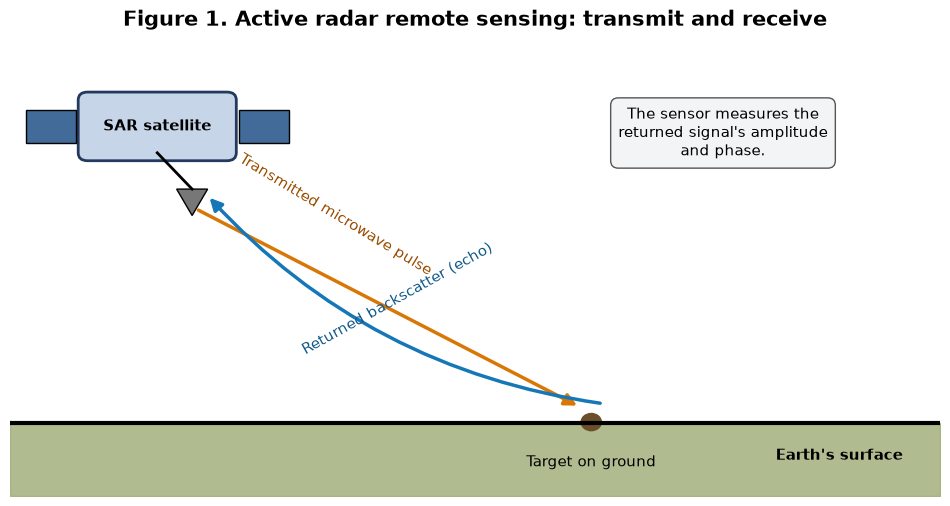

In [2]:
# Figure 1: satellite transmission and return echo
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(0, 12); ax.set_ylim(0, 7); ax.axis("off")

# Earth surface
ax.fill_between([0, 12], [1.1, 1.1], [0, 0], color="#9caa75", alpha=.8)
ax.plot([0, 12], [1.1, 1.1], lw=3, color="black")
ax.text(10.7, .55, "Earth's surface", ha="center", weight="bold")

# Satellite
sat = FancyBboxPatch((1.0, 5.2), 1.8, .8, boxstyle="round,pad=.12", fc="#c7d5e8", ec="#23395d", lw=2)
ax.add_patch(sat)
ax.text(1.9, 5.6, "SAR satellite", ha="center", va="center", weight="bold")
ax.add_patch(Rectangle((.2,5.35),.65,.5,fc="#426b9a",ec="black"))
ax.add_patch(Rectangle((2.95,5.35),.65,.5,fc="#426b9a",ec="black"))
ax.plot([1.9, 2.35], [5.2, 4.65], color="black", lw=2)
ax.add_patch(Polygon([[2.15,4.65],[2.55,4.65],[2.35,4.25]], closed=True, fc="#777777", ec="black"))

# Target
ax.add_patch(Circle((7.5,1.12),.13,color="#6b4f2a"))
ax.text(7.5,.45,"Target on ground",ha="center")

# Transmit and return paths
ax.add_patch(FancyArrowPatch((2.4,4.35),(7.35,1.35),arrowstyle="-|>",mutation_scale=18,lw=2.5,color="#d97706"))
ax.text(4.2,3.35,"Transmitted microwave pulse",rotation=-31,color="#9a4d00",ha="center")
ax.add_patch(FancyArrowPatch((7.65,1.4),(2.55,4.55),connectionstyle="arc3,rad=-.18",arrowstyle="-|>",mutation_scale=18,lw=2.5,color="#1677b8"))
ax.text(5.0,2.15,"Returned backscatter (echo)",rotation=29,color="#125b8b",ha="center")

ax.text(9.2,5.5,"The sensor measures the\nreturned signal's amplitude\nand phase.",ha="center",va="center",
        bbox=dict(boxstyle="round,pad=.5",fc="#f3f4f6",ec="#555"))
ax.set_title("Figure 1. Active radar remote sensing: transmit and receive",fontsize=15,weight="bold")
plt.show()

### Two-way travel time and slant range

The radar pulse travels from the antenna to the target and then back to the antenna. If the measured round-trip time is \(\Delta t\), the slant range is:

$$
R = \frac{c\Delta t}{2}
$$

where $c \approx 3 \times 10^8$ m/s is the speed of light. The division by two is necessary because the measured time includes both the outgoing and returning paths.

For example, a round-trip time of approximately 4.67 milliseconds corresponds to a slant range of about 700 km.


In [3]:
c = 299_792_458  # speed of light, m/s
round_trip_time = 4.67e-3
slant_range = c * round_trip_time / 2
print(f"Slant range: {slant_range/1000:,.1f} km")

Slant range: 700.0 km


## How microwave energy interacts with Earth's surface

The returned signal depends on surface roughness, dielectric properties (including moisture), geometry, wavelength, polarization, and incidence angle. Four scattering mechanisms are especially useful when interpreting SAR.


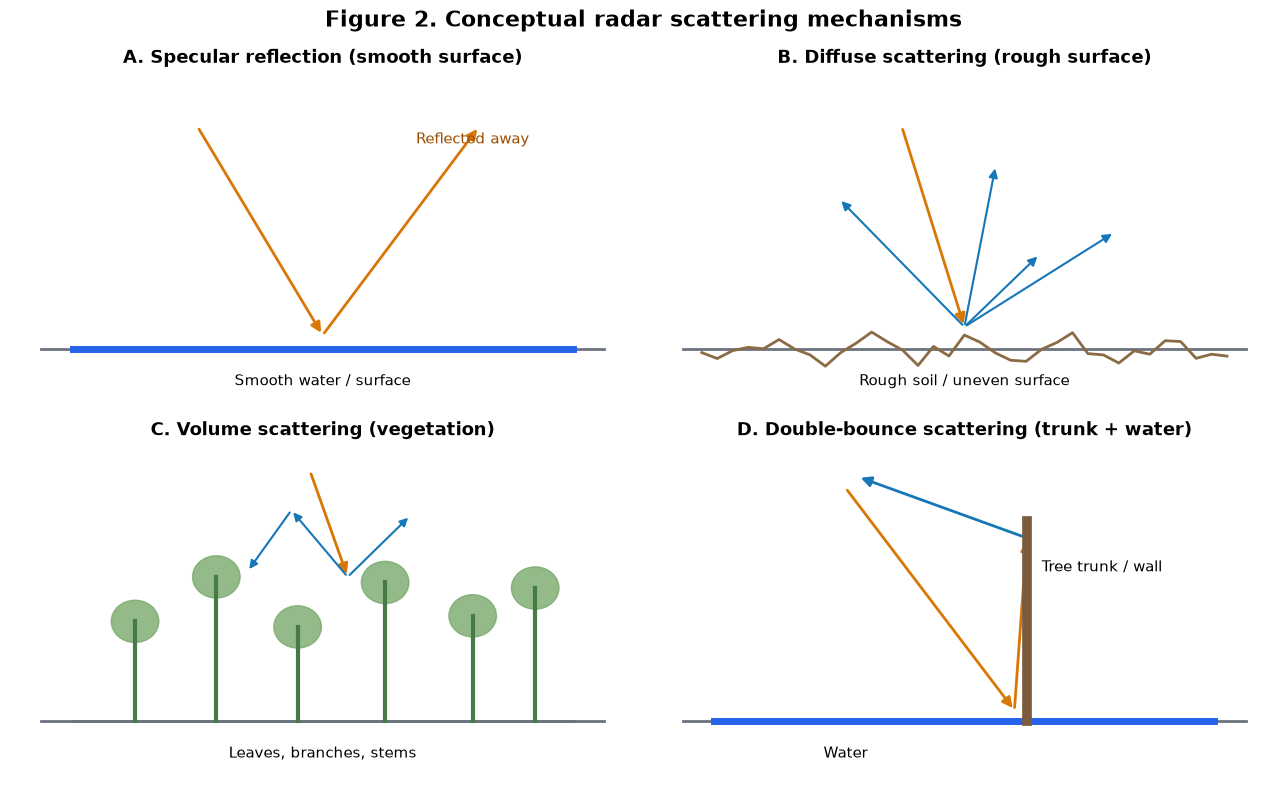

In [4]:
# Figure 2: four simplified scattering mechanisms
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
titles = ["A. Specular reflection (smooth surface)", "B. Diffuse scattering (rough surface)",
          "C. Volume scattering (vegetation)", "D. Double-bounce scattering (trunk + water)"]

for ax, title in zip(axes.flat, titles):
    ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
    ax.plot([0.5,9.5],[1,1],color="#6b7280",lw=2)
    ax.set_title(title,weight="bold")

# specular
ax=axes[0,0]
ax.plot([1,9],[1,1],color="#2563eb",lw=5)
ax.add_patch(FancyArrowPatch((3,5),(5,1.25),arrowstyle="-|>",mutation_scale=15,color="#d97706",lw=2))
ax.add_patch(FancyArrowPatch((5,1.25),(7.5,5),arrowstyle="-|>",mutation_scale=15,color="#d97706",lw=2))
ax.text(5,.35,"Smooth water / surface",ha="center")
ax.text(7.4,4.7,"Reflected away",ha="center",color="#9a4d00")

# diffuse
ax=axes[0,1]
rng=np.random.default_rng(4)
x=np.linspace(.8,9.2,35); y=1+0.18*np.sin(x*4)+0.08*rng.normal(size=len(x))
ax.plot(x,y,color="#8b6b45",lw=2)
ax.add_patch(FancyArrowPatch((4,5),(5,1.4),arrowstyle="-|>",mutation_scale=15,color="#d97706",lw=2))
for end in [(3,3.7),(5.5,4.3),(7.4,3.1),(6.2,2.7)]:
    ax.add_patch(FancyArrowPatch((5,1.4),end,arrowstyle="-|>",mutation_scale=13,color="#1677b8",lw=1.5))
ax.text(5,.35,"Rough soil / uneven surface",ha="center")

# volume
ax=axes[1,0]
ax.plot([1,9],[1,1],color="#6b7280",lw=2)
for xx,hh in [(2,2.8),(3.3,3.6),(4.6,2.7),(6,3.5),(7.4,2.9),(8.4,3.4)]:
    ax.plot([xx,xx],[1,hh],color="#477a45",lw=3)
    ax.add_patch(Circle((xx,hh),.38,color="#78a96b",alpha=.8))
ax.add_patch(FancyArrowPatch((4.8,5.5),(5.4,3.6),arrowstyle="-|>",mutation_scale=15,color="#d97706",lw=2))
for start,end in [((5.4,3.6),(4.5,4.8)),((5.4,3.6),(6.4,4.7)),((4.5,4.8),(3.8,3.7))]:
    ax.add_patch(FancyArrowPatch(start,end,arrowstyle="-|>",mutation_scale=12,color="#1677b8",lw=1.5))
ax.text(5,.35,"Leaves, branches, stems",ha="center")

# double bounce
ax=axes[1,1]
ax.plot([1,9],[1,1],color="#2563eb",lw=5)
ax.plot([6,6],[1,4.6],color="#7c5b3f",lw=7)
ax.add_patch(FancyArrowPatch((3.1,5.2),(5.8,1.2),arrowstyle="-|>",mutation_scale=15,color="#d97706",lw=2))
ax.add_patch(FancyArrowPatch((5.8,1.2),(6,4.3),arrowstyle="-|>",mutation_scale=15,color="#d97706",lw=2))
ax.add_patch(FancyArrowPatch((6,4.3),(3.3,5.4),arrowstyle="-|>",mutation_scale=15,color="#1677b8",lw=2))
ax.text(3.1,.35,"Water",ha="center"); ax.text(7.2,3.7,"Tree trunk / wall",ha="center")
fig.suptitle("Figure 2. Conceptual radar scattering mechanisms",fontsize=16,weight="bold")
plt.tight_layout()
plt.show()

### Specular reflection
A smooth surface can reflect most incident energy away from the sensor. Calm open water therefore often appears dark in SAR imagery.

### Diffuse or surface scattering
A rough surface redirects energy in many directions. Some energy returns to the sensor, often producing a stronger response than a smooth surface.

### Volume scattering
Microwave energy interacts with components inside vegetation, such as leaves, branches, and stems. Multiple scattering events can contribute to the returned signal.

### Double-bounce scattering
A signal can reflect between two approximately perpendicular surfaces, such as water and a vertical tree trunk or building wall. Flooded vegetation and some urban targets can therefore produce strong returns.

**Important:** These are simplified physical models. Real pixels often contain mixtures of scattering mechanisms.


## SAR image geometry: range, azimuth, and incidence angle

A side-looking SAR image has two principal image directions:

- **Range:** across-track direction, approximately from near range to far range.
- **Azimuth:** along-track direction, parallel to the satellite's flight path.

The incidence angle is measured between the incoming radar beam and the surface normal (a line perpendicular to the local surface).


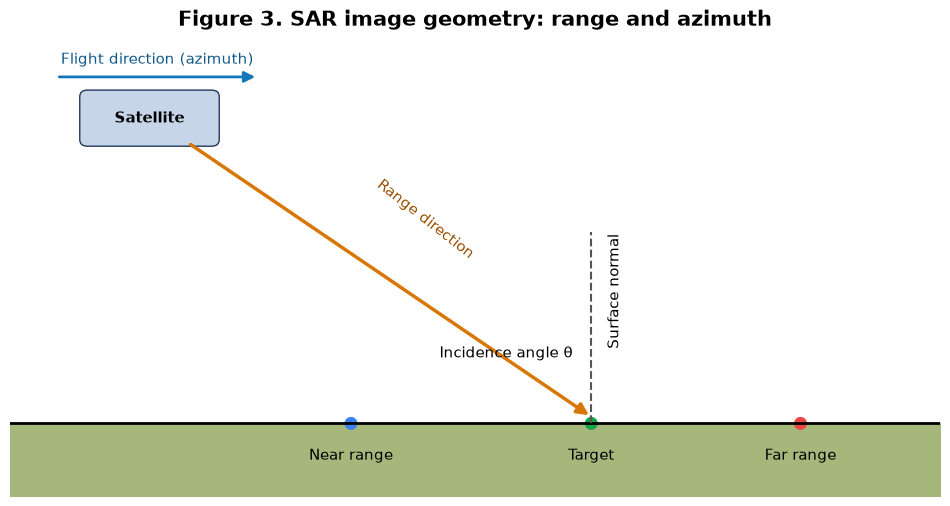

In [5]:
# Figure 3: range/azimuth geometry
fig, ax = plt.subplots(figsize=(12,6))
ax.set_xlim(0,12); ax.set_ylim(0,7); ax.axis("off")
ax.fill_between([0,12],[1.1,1.1],[0,0],color="#a6b77b")
ax.plot([0,12],[1.1,1.1],color="black",lw=2)
# satellite and orbit direction
ax.add_patch(FancyBboxPatch((1,5.4),1.6,.65,boxstyle="round,pad=.1",fc="#c7d5e8",ec="#23395d"))
ax.text(1.8,5.72,"Satellite",ha="center",va="center",weight="bold")
ax.add_patch(FancyArrowPatch((.6,6.35),(3.2,6.35),arrowstyle="-|>",mutation_scale=16,lw=2,color="#1677b8"))
ax.text(1.9,6.55,"Flight direction (azimuth)",ha="center",color="#125b8b")
# radar beam and ground points
ax.add_patch(FancyArrowPatch((2.3,5.35),(7.5,1.2),arrowstyle="-|>",mutation_scale=17,lw=2.5,color="#d97706"))
ax.text(4.7,3.6,"Range direction",rotation=-38,color="#9a4d00")
ax.scatter([4.4,7.5,10.2],[1.1,1.1,1.1],s=70,c=["#3b82f6","#16a34a","#ef4444"])
ax.text(4.4,.55,"Near range",ha="center"); ax.text(7.5,.55,"Target",ha="center"); ax.text(10.2,.55,"Far range",ha="center")
# normal and angle
ax.plot([7.5,7.5],[1.1,4.0],ls="--",color="#555")
ax.text(7.7,3.1,"Surface normal",rotation=90,va="center")
ax.text(6.4,2.1,"Incidence angle θ",rotation=0,ha="center")
ax.set_title("Figure 3. SAR image geometry: range and azimuth",fontsize=15,weight="bold")
plt.show()

## How synthetic aperture radar works

A satellite moves along its orbit while repeatedly transmitting pulses. A ground target is observed from multiple positions along the flight path. The processor combines the phase history of these echoes to focus the target in azimuth.

This is called a **synthetic aperture**: the motion of the platform is used to synthesize the effect of a much longer antenna.

The simplified diagram below shows a target being illuminated from several successive satellite positions.


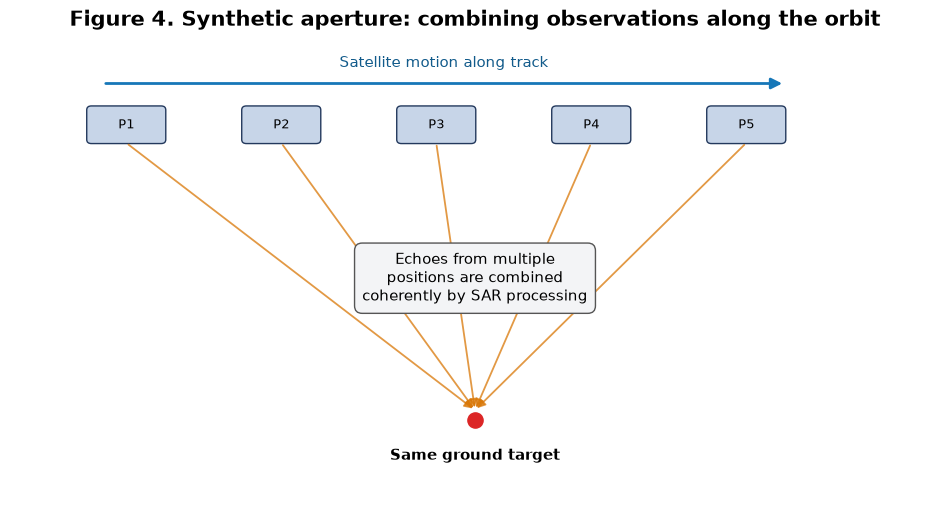

In [6]:
# Figure 4: synthetic aperture concept
fig, ax = plt.subplots(figsize=(12,6))
ax.set_xlim(0,12); ax.set_ylim(0,7); ax.axis("off")
positions=[1.5,3.5,5.5,7.5,9.5]
for i,x in enumerate(positions):
    ax.add_patch(FancyBboxPatch((x-.45,5.4),.9,.45,boxstyle="round,pad=.06",fc="#c7d5e8",ec="#23395d"))
    ax.text(x,5.62,f"P{i+1}",ha="center",va="center",fontsize=9)
    ax.add_patch(FancyArrowPatch((x,5.35),(6,1.3),arrowstyle="-|>",mutation_scale=12,
                                 lw=1.3,color="#d97706",alpha=.75))
ax.scatter([6],[1.15],s=120,c="#dc2626",zorder=5)
ax.text(6,.55,"Same ground target",ha="center",weight="bold")
ax.add_patch(FancyArrowPatch((1.2,6.25),(10,6.25),arrowstyle="-|>",mutation_scale=16,lw=2,color="#1677b8"))
ax.text(5.6,6.5,"Satellite motion along track",ha="center",color="#125b8b")
ax.text(6,3.3,"Echoes from multiple\npositions are combined\ncoherently by SAR processing",
        ha="center",va="center",bbox=dict(boxstyle="round,pad=.5",fc="#f3f4f6",ec="#555"))
ax.set_title("Figure 4. Synthetic aperture: combining observations along the orbit",fontsize=15,weight="bold")
plt.show()

## How a SAR image is organized

A focused SAR image is a two-dimensional array. Its rows and columns correspond to azimuth and range samples (the exact orientation depends on the product convention and display).

A simplified image grid:


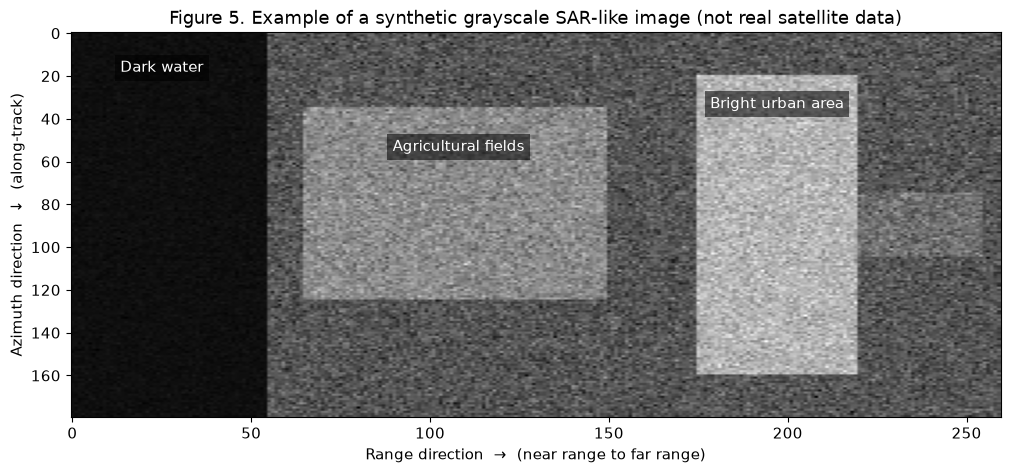

In [7]:
# Figure 5: synthetic SAR image with range and azimuth axes
rng = np.random.default_rng(12)
h,w = 180,260
img = rng.normal(0.25,0.06,(h,w))
# create illustrative regions: water, fields, urban strip, vegetation
img[:, :55] *= .18
img[35:125, 65:150] += .16
img[20:160, 175:220] += .28
img[75:105, 220:255] += .08
img = np.clip(img,0,1)
fig, ax = plt.subplots(figsize=(12,5))
ax.imshow(img,cmap="gray",vmin=0,vmax=.75,aspect="auto")
ax.set_xlabel("Range direction  →  (near range to far range)")
ax.set_ylabel("Azimuth direction  ↓  (along-track)")
ax.set_title("Figure 5. Example of a synthetic grayscale SAR-like image (not real satellite data)")
ax.text(25,18,"Dark water",color="white",ha="center",bbox=dict(fc="black",alpha=.55,ec="none"))
ax.text(108,55,"Agricultural fields",color="white",ha="center",bbox=dict(fc="black",alpha=.55,ec="none"))
ax.text(197,35,"Bright urban area",color="white",ha="center",bbox=dict(fc="black",alpha=.55,ec="none"))
plt.show()

## SAR brightness and backscatter

A SAR display often uses grayscale intensity. Dark pixels generally represent lower returned power; bright pixels represent higher returned power. Brightness is not a unique land-cover label: the same surface type can look different as moisture, roughness, incidence angle, polarization, and geometry change.

| Surface or target | Common interpretation | Important qualification |
|---|---|---|
| Calm open water | Often dark | Wind, waves, and nearby structures can brighten it |
| Bare soil | Variable gray | Strongly affected by roughness and moisture |
| Crops | Variable | Depends on crop growth stage, water, and polarization |
| Forest | Often moderate | Can be bright or dark depending on structure and wavelength |
| Buildings | Often bright | Orientation and shadowing matter |
| Flooded vegetation | Sometimes bright | Double-bounce can increase the return |

### Backscatter in decibels

For a calibrated backscatter coefficient \(\sigma^0\):

$$
\sigma^0_{dB}=10\log_{10}(\sigma^0)
$$

A negative dB value is normal. For example, a linear value of 0.01 becomes -20 dB.


In [8]:
linear_backscatter = np.array([0.001, 0.003, 0.01, 0.03, 0.1, 0.3])
db = 10 * np.log10(linear_backscatter)
for x, y in zip(linear_backscatter, db):
    print(f"σ⁰ = {x:0.3f}  ->  {y:6.2f} dB")

σ⁰ = 0.001  ->  -30.00 dB
σ⁰ = 0.003  ->  -25.23 dB
σ⁰ = 0.010  ->  -20.00 dB
σ⁰ = 0.030  ->  -15.23 dB
σ⁰ = 0.100  ->  -10.00 dB
σ⁰ = 0.300  ->   -5.23 dB


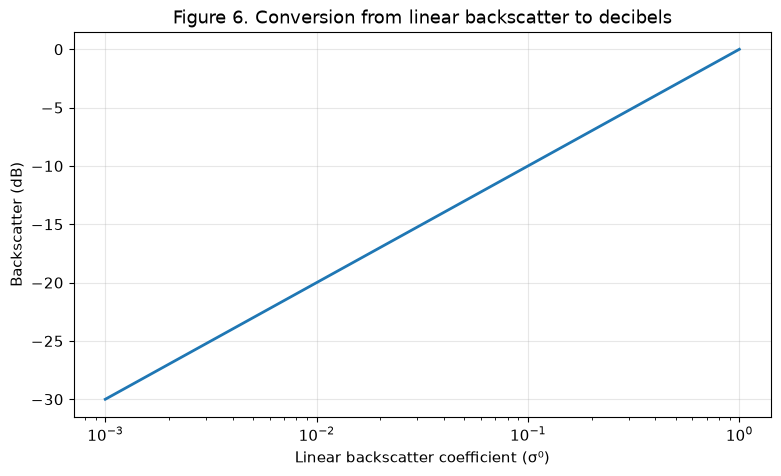

In [9]:
# Figure 6: linear backscatter to dB conversion
x = np.logspace(-3,0,300)
y = 10*np.log10(x)
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(x,y,lw=2)
ax.set_xscale("log")
ax.set_xlabel("Linear backscatter coefficient (σ⁰)")
ax.set_ylabel("Backscatter (dB)")
ax.set_title("Figure 6. Conversion from linear backscatter to decibels")
ax.grid(True,alpha=.3)
plt.show()

## Wavelength and radar bands

The relationship between wavelength $\lambda$, frequency $f$, and the speed of light $c$ is:

$$
\lambda = \frac{c}{f}
$$

Longer wavelengths generally interact with larger vegetation components and can penetrate farther into some vegetation canopies than shorter wavelengths. This is not a guarantee of penetration to the ground: canopy density, water content and structure all matter.

### X-band
- **Wavelength:** about 2.5–3.75 cm (often ~3 cm)
- **Frequency:** 8–12 GHz
- **Penetration:** very low — mainly canopy surface and fine roughness
- **Best for:** high-resolution urban mapping, infrastructure, ships, ice/snow surfaces, damage assessment
- **Common satellites:** TerraSAR-X, TanDEM-X, COSMO-SkyMed, ICEYE, Capella

### C-band
- **Wavelength:** about 3.75–7.5 cm (commonly ~5.6 cm)
- **Frequency:** 4–8 GHz
- **Penetration:** limited — upper canopy and agricultural soil moisture
- **Best for:** agriculture, flood mapping, land cover, InSAR deformation, sea ice and oceans
- **Common satellites:** Sentinel-1, RADARSAT-2, RADARSAT Constellation, Gaofen-3

### L-band
- **Wavelength:** about 15–30 cm (commonly ~23–24 cm)
- **Frequency:** 1–2 GHz
- **Penetration:** high — canopy volume, trunks, sometimes ground; dry soil and sand
- **Best for:** forest biomass and structure, deformation under vegetation, soil moisture in vegetated areas
- **Common satellites:** ALOS-2 (PALSAR-2), SAOCOM, NISAR (L-band); P-band (e.g. BIOMASS) penetrates even deeper

### Comparison

| Feature | X-band (~3 cm) | C-band (~6 cm) | L-band (~23 cm) |
|---|---|---|---|
| Penetration | Very low | Limited | High |
| Main interaction | Canopy surface | Upper canopy | Volume + ground |
| Resolution potential | Highest | High | Moderate |
| Sensitivity to biomass | Low | Moderate | High |
| Best environment | Urban, bare surface | Agriculture, floods | Forests, dense vegetation |

**Rule of thumb:** see the surface clearly → X-band; all-rounder → C-band; look into or through vegetation → L-band.


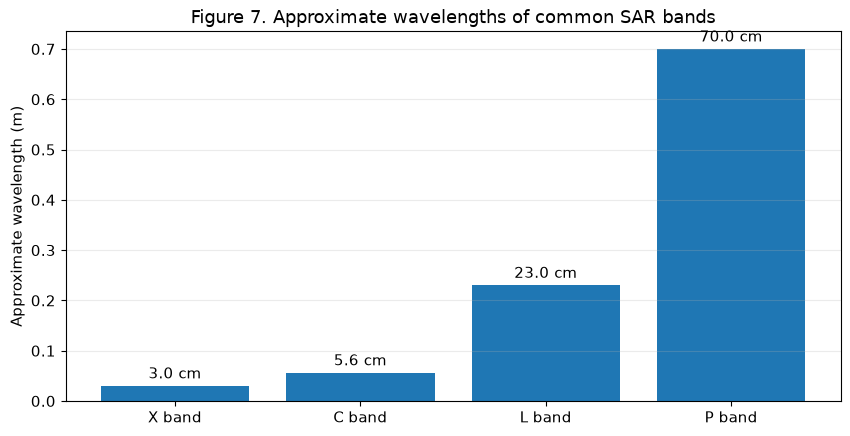

In [10]:
# Figure 7: approximate radar band wavelengths
bands = {"X band": 0.03, "C band": 0.056, "L band": 0.23, "P band": 0.70}
fig, ax = plt.subplots(figsize=(10,4.8))
names=list(bands.keys()); vals=list(bands.values())
bars=ax.bar(names,vals)
ax.set_ylabel("Approximate wavelength (m)")
ax.set_title("Figure 7. Approximate wavelengths of common SAR bands")
ax.grid(axis="y",alpha=.25)
for b,v in zip(bars,vals):
    ax.text(b.get_x()+b.get_width()/2,v+.015,f"{v*100:.1f} cm",ha="center")
plt.show()

![Radar bands X, C and L: wavelength and penetration](images/clean-educational-scientific-illustration.jpg)


## Polarization

Polarization describes the orientation of the transmitted and received electric field (VV, VH, HH, HV).


![Radar polarization: VV, VH, HH and HV](images/polarization.jpg)


| Polarization | Transmit | Receive | Type | Main interaction | Typical appearance |
|---|---|---|---|---|---|
| **VV** | Vertical | Vertical | Co-polarized | Surface scattering (soil, water, roads) | Bright on smooth surfaces |
| **HH** | Horizontal | Horizontal | Co-polarized | Surface + double-bounce (buildings, trunks) | Bright on man-made structures |
| **VH** | Vertical | Horizontal | Cross-polarized | Volume scattering (vegetation, forests) | Brighter in forests and crops |
| **HV** | Horizontal | Vertical | Cross-polarized | Volume scattering (same as VH) | Similar to VH |

**Co-polarized channels (VV and HH)** send and receive in the same orientation. They respond strongly to surface scattering; HH is especially sensitive to double-bounce.

**Cross-polarized channels (VH and HV)** send in one orientation and receive in the perpendicular orientation. Energy is rotated by multiple scattering in volumes, so forests and dense crops appear brighter.

**Practical use:** VV for soil moisture, water and agriculture; HH for urban structure; VH/HV for vegetation density. Many missions acquire dual or quad polarisation so these channels can be combined.


## Typical SAR image processing workflow

A Sentinel-1 workflow commonly includes the following steps. The exact sequence depends on the product, application, and software.

1. **Select data:** Choose acquisition dates, orbit direction, mode, and polarization.
2. **Apply orbit information:** Improve the satellite's position and velocity metadata.
3. **Remove thermal noise:** Reduce instrument-related noise where appropriate.
4. **Radiometric calibration:** Convert digital measurements to a calibrated backscatter quantity such as \(\sigma^0\), \(\beta^0\), or \(\gamma^0\).
5. **Speckle filtering (optional):** Reduce granular speckle while balancing detail preservation.
6. **Terrain correction:** Account for terrain-related geometric distortions using a DEM.
7. **Geocoding:** Place the image into a map coordinate reference system.
8. **Convert to dB (often for display/analysis):** Apply \(10\log_{10}\) to power backscatter.
9. **Analyze:** Classify water, monitor crops, estimate change, or study surface properties.

**Important:** Speckle filtering and dB conversion are not substitutes for radiometric calibration or terrain correction.


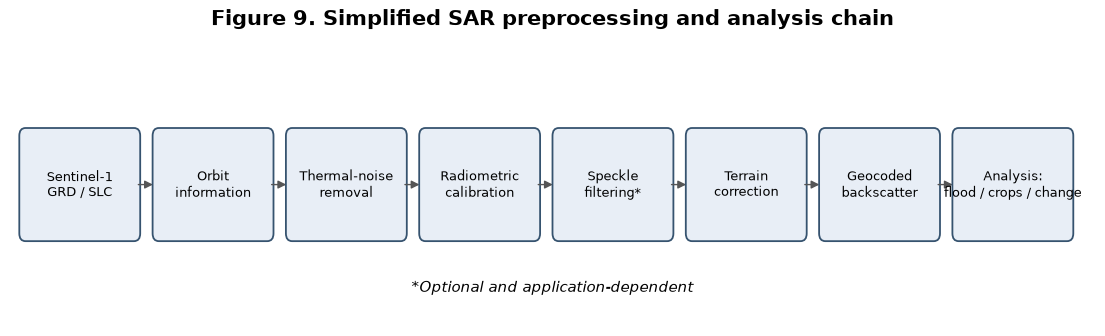

In [11]:
# Figure 9: processing workflow
steps = [
    "Sentinel-1\nGRD / SLC",
    "Orbit\ninformation",
    "Thermal-noise\nremoval",
    "Radiometric\ncalibration",
    "Speckle\nfiltering*",
    "Terrain\ncorrection",
    "Geocoded\nbackscatter",
    "Analysis:\nflood / crops / change"
]
fig, ax=plt.subplots(figsize=(14,3.8))
ax.set_xlim(0,14); ax.set_ylim(0,3); ax.axis("off")
for i,s in enumerate(steps):
    x=.2+i*1.72
    box=FancyBboxPatch((x,.95),1.4,1.0,boxstyle="round,pad=.08",fc="#e8eef6",ec="#36536f",lw=1.3)
    ax.add_patch(box); ax.text(x+.7,1.45,s,ha="center",va="center",fontsize=9)
    if i<len(steps)-1:
        ax.add_patch(FancyArrowPatch((x+1.42,1.45),(x+1.68,1.45),arrowstyle="-|>",mutation_scale=12,color="#555"))
ax.text(7,.35,"*Optional and application-dependent",ha="center",style="italic")
ax.set_title("Figure 9. Simplified SAR preprocessing and analysis chain",fontsize=15,weight="bold")
plt.show()

## Application: detecting floods with Sentinel-1

Open water often appears dark in SAR because a smooth water surface reflects much of the radar energy away from the sensor. A simple change-detection measure is:

$$
\Delta VV = VV_{flood} - VV_{pre-flood}
$$

A large negative change can indicate newly inundated smooth surfaces. But this is not a universal flood rule: flooded vegetation may brighten due to double-bounce scattering, and wind-roughened water may be bright.

A robust flood workflow should consider:
- Pre-flood and flood-season images with comparable acquisition geometry.
- VV and VH channels.
- Permanent water masks.
- Terrain and slope.
- Vegetation and urban areas.
- Temporal consistency and validation data.


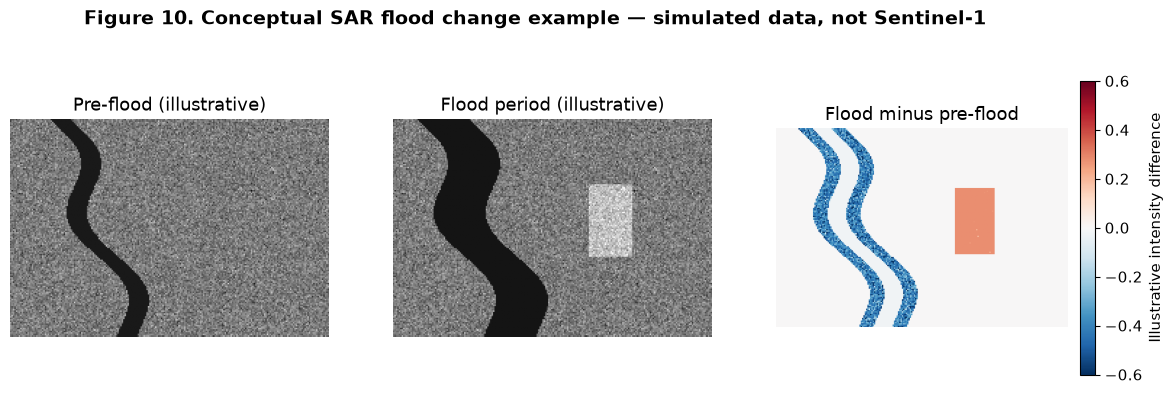

In [12]:
# Figure 10: illustrative pre-flood and flood images
rng=np.random.default_rng(8)
base=np.clip(rng.normal(.48,.10,(150,220)),0,1)
pre=base.copy()
# river channel
for r in range(150):
    c=int(35+0.35*r+12*np.sin(r/15))
    pre[r,max(0,c-7):min(220,c+7)] = .10
flood=base.copy()
for r in range(150):
    c=int(35+0.35*r+12*np.sin(r/15))
    flood[r,max(0,c-18):min(220,c+18)] = .08
# some bright flooded vegetation patches
flood[45:95,135:165] = np.clip(flood[45:95,135:165]+.28,0,1)

fig,axes=plt.subplots(1,3,figsize=(14,4.5))
axes[0].imshow(pre,cmap="gray",vmin=0,vmax=1); axes[0].set_title("Pre-flood (illustrative)")
axes[1].imshow(flood,cmap="gray",vmin=0,vmax=1); axes[1].set_title("Flood period (illustrative)")
change=flood-pre
im=axes[2].imshow(change,cmap="RdBu_r",vmin=-.6,vmax=.6); axes[2].set_title("Flood minus pre-flood")
for ax in axes: ax.axis("off")
fig.colorbar(im,ax=axes[2],fraction=.046,pad=.04,label="Illustrative intensity difference")
fig.suptitle("Figure 10. Conceptual SAR flood change example — simulated data, not Sentinel-1",fontsize=14,weight="bold")
plt.show()

### Why flooded vegetation can be different

Open water may have low backscatter, but water beneath upright stems, trunks, or buildings can create double-bounce paths. The resulting return may be stronger than before flooding. This is why flood mapping in wetlands, mangroves, and crop fields should not rely exclusively on a single low-backscatter threshold.


## SAR versus optical imagery

| Characteristic | SAR | Optical |
|---|---|---|
| Energy source | Active microwave transmission | Reflected sunlight |
| Night acquisition | Yes | Normally no |
| Cloud sensitivity | Generally low | High |
| Surface roughness | Directly influences scattering | Less directly measured |
| Moisture sensitivity | Often strong | Mostly indirect |
| Vegetation information | Structure and water-related interactions | Spectral and biochemical properties |

SAR and optical data are complementary. Combining Sentinel-1 with Sentinel-2 can improve land-cover, crop, and flood analyses.


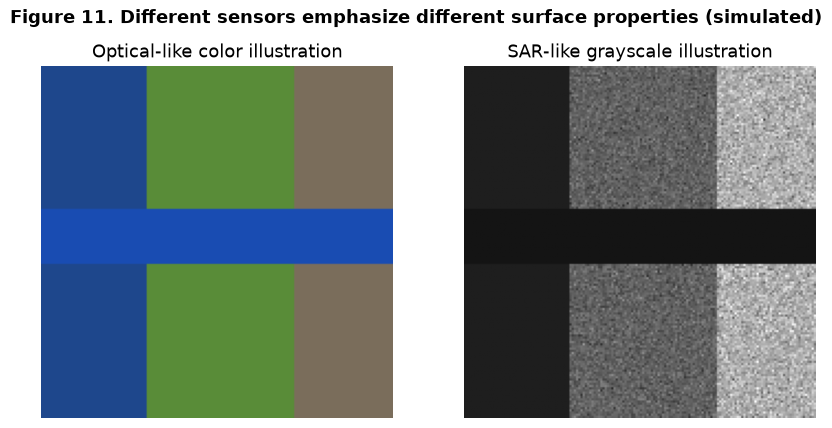

In [13]:
# Figure 11: conceptual side-by-side optical and SAR appearance
rng=np.random.default_rng(22)
n=160
opt=np.zeros((n,n,3))
sar=np.zeros((n,n))
# fields
for r in range(n):
    for c in range(n):
        if c < 48:
            opt[r,c]=[.12,.28,.55]; sar[r,c]=.12
        elif 48 <= c < 115:
            opt[r,c]=[.35,.55,.22]; sar[r,c]=.38+rng.normal(0,.06)
        else:
            opt[r,c]=[.48,.43,.36]; sar[r,c]=.68+rng.normal(0,.10)
# water strip
opt[65:90,:]=[.10,.30,.70]; sar[65:90,:]=.08
opt=np.clip(opt,0,1); sar=np.clip(sar,0,1)
fig,axes=plt.subplots(1,2,figsize=(10,4.8))
axes[0].imshow(opt); axes[0].set_title("Optical-like color illustration")
axes[1].imshow(sar,cmap="gray",vmin=0,vmax=1); axes[1].set_title("SAR-like grayscale illustration")
for ax in axes: ax.axis("off")
fig.suptitle("Figure 11. Different sensors emphasize different surface properties (simulated)",weight="bold")
plt.show()

## Quick knowledge check

Answer these questions after reviewing the notebook.

1. Why does calm open water often appear dark in a SAR image?
2. What is the difference between range and azimuth?
3. Why is SAR called a synthetic aperture?
4. What does a negative backscatter value in dB mean?
5. Why can flooded vegetation become brighter instead of darker?
6. What is the difference between VV and VH polarization?
7. Why is terrain correction important?

### Suggested answers
1. Smooth water often reflects energy away from the antenna, producing a weak return.
2. Range is across-track; azimuth is along-track.
3. The platform's motion allows the processor to combine echoes from multiple positions, synthesizing a longer aperture.
4. It means the linear backscatter coefficient is between zero and one; this is normal for many calibrated SAR measurements.
5. Double-bounce scattering between water and vertical vegetation structures can strengthen the return.
6. VV is vertical transmit/vertical receive; VH is vertical transmit/horizontal receive.
7. Terrain can distort the apparent location and shape of features; a DEM helps correct geometry and geolocate pixels.


## SAR in GeoLattice: `geolattice.rsense.sar`

GeoLattice puts its radar toolkit in **`geolattice.rsense.sar`**, which maps to the source package `src/rsense/sar/`. Import it as part of the remote-sensing namespace:

```python
import geolattice.rsense as rs
from geolattice.rsense import sar          # or: from geolattice.rsense.sar import to_db, process_grd, ...
```

Install the SAR extras with the remote-sensing stack:

```bash
pip install "geolattice[rsense]"       # core raster + optical + SAR helpers
pip install "geolattice[rsense-all]"   # SAR, InSAR, lidar, UAV, ML/DL, viz, scaling
```

The package is organised around the jobs you actually do with radar data:

| Job | What `geolattice.rsense.sar` provides |
|---|---|
| **Read and calibrate** | Sentinel-1 GRD/SLC helpers (`process_grd`, `read_grd_subset`, `calibrate`, `to_db` / `from_db`), RCM Level-1 readers, NISAR HDF5 readers |
| **Clean the image** | Speckle filters (`boxcar`, `lee`, `refined_lee`, `gamma_map`, `multitemporal`), multilooking, border-noise removal |
| **Geometry** | Incidence grids, terrain flattening / correction, layover–shadow masks, TOPS burst handling for InSAR prep |
| **Polarimetry** | Dual-pol features, H/A/α, Stokes, m-χ / m-δ, compact-pol conversion for RCM |
| **Change and applications** | Log-ratio and omnibus change, flood / rice / ship / oil-spill maps, dual-pol vegetation indices |
| **Mission-specific** | `sentinel1`, `radarsat`, `nisar`, plus `ship` detection with AIS matching |

Downstream notebooks in this chapter call these functions on real Sentinel-1, RCM and NISAR products. The hands-on half of *this* notebook starts with the lighter helpers (`to_db`, `from_db`, `enl_estimate`) and a simulated Sentinel-1 scene.


In [14]:
# Confirm that geolattice.rsense.sar imports and list its top-level submodules.
import geolattice
import geolattice.rsense as rs
from geolattice.rsense import sar

print("geolattice", getattr(geolattice, "__version__", "?"))
print("backend:", rs.get_backend(), "| available:", rs.available_backends())
print("sar package:", sar.__name__)
print("submodules:", ", ".join(
    name for name in ("sentinel1", "speckle", "polsar", "change", "apps",
                      "sar_indices", "radarsat", "nisar", "ship")
    if hasattr(sar, name)
))

geolattice 0.3.49


backend: cpu | available: ['cpu', 'cuda']
sar package: geolattice.rsense.sar
submodules: sentinel1, speckle, polsar, change, apps, sar_indices, radarsat, nisar, ship


In [15]:
# Walk the public API of each src/rsense/sar submodule and summarise it as a table.
import importlib
import inspect
import pandas as pd

SUBMODULES = [
    "sentinel1", "speckle", "polsar", "change", "apps",
    "sar_indices", "radarsat", "nisar", "ship",
]

rows = []
for name in SUBMODULES:
    mod = importlib.import_module(f"geolattice.rsense.sar.{name}")
    for attr_name, obj in sorted(vars(mod).items()):
        if attr_name.startswith("_"):
            continue
        if not (inspect.isfunction(obj) or inspect.isclass(obj)):
            continue
        # keep only objects defined in this submodule (skip re-exports)
        if getattr(obj, "__module__", None) != mod.__name__:
            continue
        kind = "class" if inspect.isclass(obj) else "function"
        doc = (inspect.getdoc(obj) or "").split("\n")[0]
        rows.append({
            "submodule": name,
            "kind": kind,
            "name": attr_name,
            "summary": doc[:110],
        })

api = pd.DataFrame(rows)
print(api.groupby("submodule").size().rename("n").to_string())
print()
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 40)
for sub, grp in api.groupby("submodule", sort=False):
    print(f"=== geolattice.rsense.sar.{sub} ({len(grp)}) ===")
    print(grp[["kind", "name", "summary"]].head(8).to_string(index=False))
    if len(grp) > 8:
        print(f"  ... +{len(grp) - 8} more")
    print()

submodule
apps            8
change          6
nisar          12
polsar         10
radarsat       21
sar_indices    10
sentinel1      45
ship           21
speckle         7

=== geolattice.rsense.sar.sentinel1 (45) ===
    kind              name                                                                                            summary
function      apply_offset     Shift an image or ``(..., y, x)`` stack by whole pixels on its own grid (NaN where uncovered).
function  apply_orbit_file           ``Apply-Orbit-File``: return a copy of ``ann`` (:func:`read_slc_annotation`) whose orbit
function      back_geocode                   DEM-assisted co-registration (SNAP ``Back-Geocoding``) of a secondary burst to a
function burst_coordinates Fractional (line, sample) in a burst for zero-Doppler times and slant ranges from :func:`geo2rdr`.
function      burst_window           Range-sample window ``(start, stop)`` of a burst covering lon/lat ``bounds`` (TOPS-Split
function         calibrate

## Notebooks in this chapter

All notebooks live in `Tutorials/notebooks/08_remote_sensing/08_03_radar/`. Work through them in order within each mission block.

### Fundamentals

| Notebook | Topic |
|---|---|
| `09_03_00_sar_fundamentals.ipynb` | SAR fundamentals, visual walkthrough, and `geolattice.rsense.sar` (this notebook) |

### Sentinel-1

| Notebook | Topic |
|---|---|
| `09_03_01_00_sentinel_1_sar.ipynb` | Sentinel-1 SAR introduction |
| `09_03_01_01_sentinel_1_sar_processing.ipynb` | Sentinel-1 SAR processing |
| `09_03_01_02_sentinel_1_grd_processing.ipynb` | Sentinel-1 GRD processing |
| `09_03_01_03_sentinel_1_multitemporal_grd_time_series_deforestation_around_the_rohingya_camps_2017.ipynb` | Multitemporal GRD time series (Rohingya camps, 2017) |
| `09_03_01_04_topographic_insar_a_dem_from_a_sentinel_1_slc_pair.ipynb` | Topographic InSAR: DEM from a Sentinel-1 SLC pair |
| `09_03_01_05_differential_insar_dinsar.ipynb` | Differential InSAR (DInSAR) |
| `09_03_01_06_sbas_small_baseline_subset_insar.ipynb` | SBAS (Small Baseline Subset) InSAR |
| `09_03_01_07_persistent_scatterer_insar_ps_insar.ipynb` | Persistent Scatterer InSAR (PS-InSAR) |
| `09_03_01_08_dual_pol_polarimetric_decomposition_slc.ipynb` | Dual-pol polarimetric decomposition (SLC) |
| `09_03_01_09_interferometric_coherence_of_slcs.ipynb` | Interferometric coherence of SLCs |
| `09_03_01_10_sentinel_1_based_indices.ipynb` | Sentinel-1 based indices |

### RADARSAT Constellation Mission (RCM)

| Notebook | Topic |
|---|---|
| `09_03_02_00_radarsat_constellation_mission_rcm.ipynb` | RCM introduction |
| `09_03_02_01_radarsat_constellation_mission_rcm_processing.ipynb` | RCM processing |
| `09_03_02_02_radarsat_grd_data.ipynb` | RADARSAT GRD data |
| `09_03_02_03_radarsat_constellation_mission_rcm_insar_processing.ipynb` | RCM InSAR processing |
| `09_03_02_04_radarsat_polarimetric_sar_polsar.ipynb` | RADARSAT polarimetric SAR (PolSAR) |
| `09_03_02_05_compact_polarimetry_cp.ipynb` | Compact polarimetry (CP) |

### NISAR

| Notebook | Topic |
|---|---|
| `09_03_03_00_nisar_nasa_isro_synthetic_aperture_radar.ipynb` | NISAR introduction |
| `09_03_03_01_nisar_processing.ipynb` | NISAR processing |
| `09_03_03_02_nisar_rslc_range_doppler_single_look_complex_processing.ipynb` | NISAR RSLC (range-Doppler SLC) |
| `09_03_03_03_nisar_gslc_geocoded_single_look_complex_processing.ipynb` | NISAR GSLC (geocoded SLC) |
| `09_03_03_04_nisar_gcov_geocoded_polarimetric_covariance_processing.ipynb` | NISAR GCOV (geocoded polarimetric covariance) |
| `09_03_03_05_nisar_gunw_geocoded_unwrapped_interferogram.ipynb` | NISAR GUNW (geocoded unwrapped interferogram) |


## Data

| Data | Type |
|---|---|
| Sentinel-1 VV backscatter, 9 Mar 2015, 20 m, terrain-corrected (pyroSAR test product) | **Real** |
| Sentinel-1B GRD annotation, 23 Dec 2021 (central Italy) | **Real** metadata |
| Landsat 7 composite + 90 m DEM, Mono Lake / Long Valley, California | **Real** landscape used by the simulator |
| Sentinel-1-like scenes from `sar_simulator.py` | **Simulated** from the real landscape (see below) |

> **About the simulator.** Real Sentinel-1 time series and interferometric pairs are tens of
> gigabytes and need online accounts, which were unavailable when these notebooks were executed.
> `sar_simulator.py` (shipped with the notebooks, fully commented) therefore generates
> Sentinel-1-like data from a *real* land-cover map and *real* terrain, applying the physics
> taught here. Real-data loaders (`rs.sar.load_rtc`, ASF, HyP3) are shown under
> `RUN_ONLINE = True` and accept the same downstream code.


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [16]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings to keep the output short

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters (DataArray, Dataset)
import rasterio  # GeoTIFF reading
import matplotlib.pyplot as plt  # figures
from scipy import stats  # probability distributions (Rayleigh, exponential, gamma)

import geolattice.rsense as rs  # GeoLattice remote sensing: reading, SAR helpers and plotting
from geolattice.rsense.sar import sentinel1 as s1  # Sentinel-1 annotation readers
from geolattice.rsense.get_images import get_images, search_images  # search and download satellite images
import sar_simulator as sim  # local helper module that simulates SAR backscatter for the study area

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
RUN_ONLINE = False  # set to True to run the online search and download example at the end

In [17]:
from pathlib import Path  # file paths
import urllib.request  # download files over HTTP

DATA = Path("../../../../Data/08_remote_sensing/08_03_radar")  # data folder next to the notebook
DATA.mkdir(exist_ok=True)  # create it if needed
GH = "https://github.com/opengeos/datasets/releases/download"  # base URL of the opengeos datasets release
RAW = "https://raw.githubusercontent.com"  # base URL for raw GitHub files
# folder of a real Sentinel-1B GRD annotation in the sarsen test data
S1 = (f"{RAW}/bopen/sarsen/main/tests/data/"
      "S1B_IW_GRDH_1SDV_20211223T051122_20211223T051147_030148_039993_5371.SAFE/annotation")
N1 = "s1b-iw-grd-vv-20211223t051122-20211223t051147-030148-039993-001"  # file name of the VV annotation XML
URLS = {  # file name -> download URL
    "landsat.tif": f"{GH}/raster/landsat.tif",        # Landsat 7 composite, central Sierra Nevada
    "dem_90m.tif": f"{GH}/book/dem_90m.tif",          # 90 m DEM, same region
    # Real Sentinel-1 VV backscatter (dB), terrain-corrected with GAMMA, 20 m (pyroSAR test data)
    # real Sentinel-1 VV backscatter (dB), terrain-corrected, 20 m
    "s1_vv_db.tif": f"{RAW}/johntruckenbrodt/pyroSAR/main/tests/data/S1A__IW___A_20150309T173017_VV_grd_mli_geo_norm_db.tif",
    # Real Sentinel-1B GRD annotation XML (23 Dec 2021, central Italy): geometry and acquisition
    # metadata, read below with geolattice.rsense.sar.sentinel1's own annotation-XML parsers rather
    # than by hand. (Section 2 of 07_03_02_sentinel1_grd.ipynb covers the matching calibration
    # and noise XML -- the calibration LUT reading they drive -- in depth.)
    "s1_annotation.xml": f"{S1}/{N1}.xml",  # the annotation XML
}

def fetch(name):  # download helper
    """Download a tutorial dataset once and return its local path."""
    path = DATA / name  # local path of the file
    if not path.exists():  # download only if the file is not there yet
        print(f"Downloading {name} ...")  # progress message
        urllib.request.urlretrieve(URLS[name], path)  # copy the URL to the local path
    return path  # return the local path either way

## Microwave bands, penetration and roughness

Longer wavelengths penetrate deeper into vegetation, dry soil and snow, and "see" surfaces as
smoother. The **Rayleigh criterion** calls a surface smooth (mirror-like, dark) when its height
variation is below λ / (8 cos θ).


In [18]:
bands = pd.DataFrame([  # radar bands, their wavelengths, missions and what they mainly interact with
    ("X", 3.1, "TerraSAR-X, COSMO-SkyMed, ICEYE, Capella", "Leaves, crop tops, ice surface"),
    ("C", 5.55, "Sentinel-1, RADARSAT Constellation", "Upper canopy, crops, soil moisture"),
    ("S", 9.4, "NISAR (S-band), NovaSAR", "Crowns and branches"),
    ("L", 24.0, "ALOS-2/4, NISAR (L-band), SAOCOM", "Branches, trunks, deforming ground"),
    ("P", 69.0, "BIOMASS", "Trunks and ground beneath forest"),
], columns=["Band", "Wavelength (cm)", "Missions", "Mainly interacts with"])  # column names
theta = 35  # incidence angle (degrees) used for the roughness criterion
# Rayleigh criterion: a surface looks smooth if its height variation is below lambda / (8 cos theta)
bands["Smooth if height variation < (cm)"] = (bands["Wavelength (cm)"] / (8 * np.cos(np.radians(theta)))).round(2)
bands  # show the table

,Band,Wavelength (cm),Missions,Mainly interacts with,Smooth if height variation < (cm)
0,X,3.10,"TerraSAR-X, COSMO-SkyMed, ICEYE, Capella","Leaves, crop tops, ice surface",0.47
1,C,5.55,"Sentinel-1, RADARSAT Constellation","Upper canopy, crops, soil moisture",0.85
2,S,9.40,"NISAR (S-band), NovaSAR",Crowns and branches,1.43
3,L,24.00,"ALOS-2/4, NISAR (L-band), SAOCOM","Branches, trunks, deforming ground",3.66
4,P,69.00,BIOMASS,Trunks and ground beneath forest,10.53


At C-band a field with 1 cm clods already looks rough (bright), while at L-band it appears
smooth. Calm water is smooth at every wavelength, which is why lakes are black in SAR images.


## Imaging geometry
SAR looks *sideways*. Range (across-track) resolution comes from pulse bandwidth and is finer in
ground range at steeper incidence; azimuth (along-track) resolution comes from synthesising a long
antenna, ideally half the physical antenna length, independent of range.


In [19]:
c = 299_792_458.0  # speed of light (m/s)
bw = 56.5e6                                   # Sentinel-1 IW range bandwidth (Hz), sub-swath IW1
slant_res = c / (2 * bw)  # slant-range resolution = c / (2 x bandwidth)
inc = np.array([30, 35, 40, 45])  # a range of incidence angles (degrees)
# ground-range resolution = slant-range resolution / sin(incidence)
pd.DataFrame({"incidence (°)": inc, "slant-range resolution (m)": round(slant_res, 2),
              "ground-range resolution (m)": (slant_res / np.sin(np.radians(inc))).round(2)})

,incidence (°),slant-range resolution (m),ground-range resolution (m)
0,30,2.65,5.31
1,35,2.65,4.63
2,40,2.65,4.13
3,45,2.65,3.75


Because the image is built from *distance* to the sensor, terrain distorts it:

- **Foreshortening**: slopes facing the radar are compressed (bright, narrow).
- **Layover**: if a slope is steeper than the incidence angle, its top is closer to the radar than
  its foot and is imaged *before* it.
- **Shadow**: slopes facing away, steeper than 90° − θ, receive no signal.

Let's trace these along a real west-east profile across the Sierra Nevada escarpment, with the
radar looking east (ascending pass) at 35°.


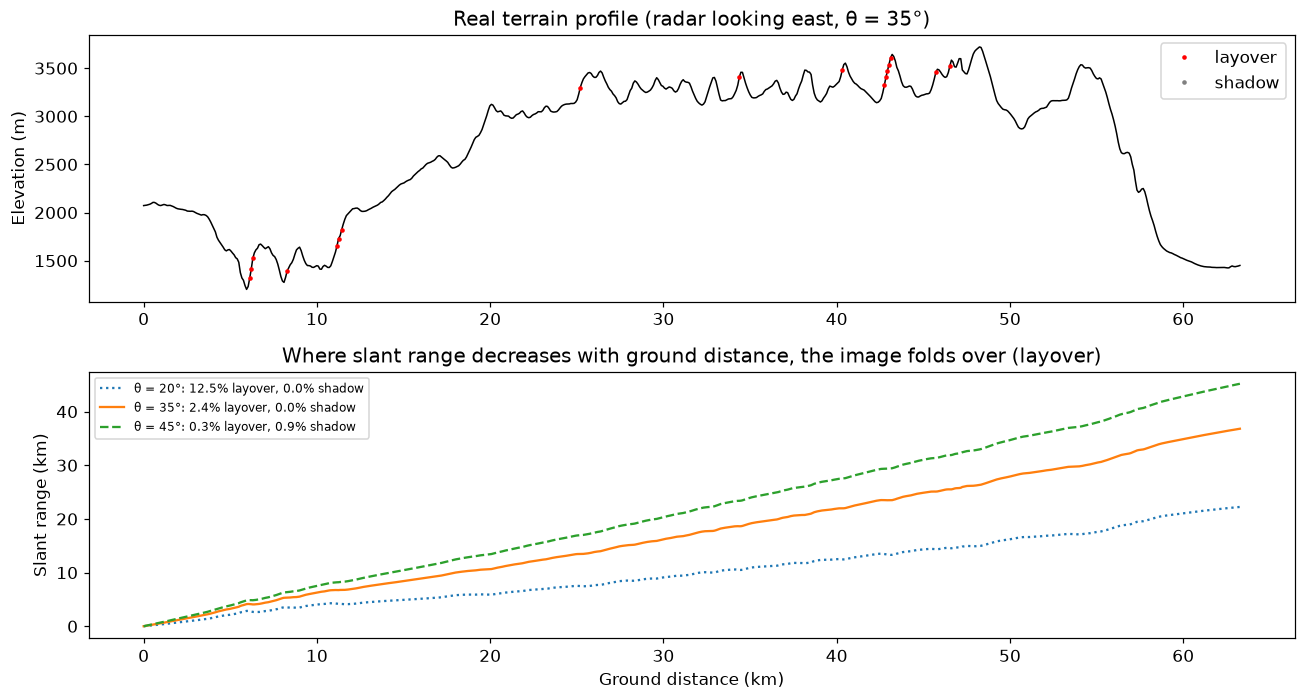

In [20]:
# simulated scene (elevation, land cover) and the Landsat image of the same area
scene, optical = sim.study_area(fetch("landsat.tif"), fetch("dem_90m.tif"))
row = int(np.nanargmax(np.nanstd(scene.elevation.values, axis=1)))       # most rugged row
z = scene.elevation.isel(y=row).values.astype(float)  # elevation profile along that row
x = (scene.x.values - scene.x.values[0]).astype(float)  # distance from the first pixel along the row (m)
ok = np.isfinite(z); x, z = x[ok], z[ok]  # keep only valid elevations

# slant range, layover and shadow along a terrain profile for one incidence angle
def profile_geometry(x, z, theta_deg):
    th = np.radians(theta_deg)  # incidence angle in radians
    r = x * np.sin(th) - z * np.cos(th)          # slant-range coordinate (far-field)
    p = x * np.cos(th) + z * np.sin(th)          # constant along a beam line
    layover = np.r_[False, np.diff(r) < 0]  # layover where slant range decreases as ground distance increases
    # shadow where the terrain is hidden behind earlier terrain along the beam
    shadow = np.r_[False, p[1:] < np.maximum.accumulate(p)[:-1]]
    return r, layover, shadow  # return the three arrays

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))  # terrain (top) and slant range (bottom)
for th, ls in [(20, ":"), (35, "-"), (45, "--")]:  # three incidence angles, each with its own line style
    r, lay, sh = profile_geometry(x, z, th)  # geometry for this angle
    if th == 35:  # draw the terrain and its distortions only once, for 35 degrees
        axes[0].plot(x / 1000, z, "k-", lw=1)  # terrain profile
        axes[0].plot(x[lay] / 1000, z[lay], "r.", ms=4, label="layover")  # layover points in red
        axes[0].plot(x[sh] / 1000, z[sh], ".", color="grey", ms=4, label="shadow")  # shadow points in grey
    # slant range against ground distance, with the layover and shadow shares
    axes[1].plot(x / 1000, (r - r[0]) / 1000, ls, label=f"θ = {th}°: {lay.mean():.1%} layover, {sh.mean():.1%} shadow")
# labels and legend of the top panel
axes[0].set(ylabel="Elevation (m)", title="Real terrain profile (radar looking east, θ = 35°)"); axes[0].legend()
axes[1].set(xlabel="Ground distance (km)", ylabel="Slant range (km)",  # labels of the bottom panel
            title="Where slant range decreases with ground distance, the image folds over (layover)")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()  # legend, arrange and draw

Steep incidence (20°) causes much more layover; shallow incidence (45°) causes more shadow.
Sentinel-1 IW spans roughly 30-46°, a compromise. In mountains, combining ascending and
descending passes (looking east and west) fills many gaps.


## Scattering mechanisms and incidence angle
| Mechanism | Where | Signature |
|---|---|---|
| Specular / surface | Calm water, smooth bare soil, roads | Dark; drops quickly with incidence angle |
| Rough surface | Ploughed fields, rock | Moderate; VV ≫ VH |
| Volume | Forest canopies, crops, dry snow | Bright VH (depolarisation), weak angle dependence |
| Double bounce | Buildings, flooded forest, ships | Very bright (corner reflector) |

The simulator encodes typical C-band values for each class. Their dependence on incidence angle
explains why images must be normalised before comparing near and far range.


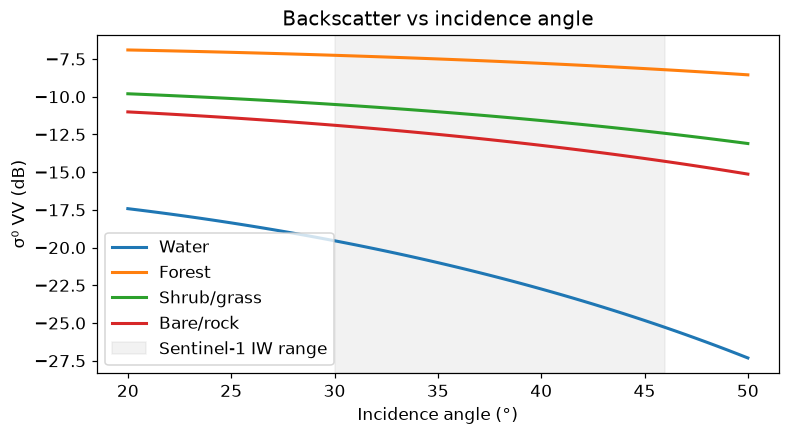

,VV at 35° (dB),VH at 35° (dB),angular exponent n
Water,-21.0,-29.0,6.0
Forest,-7.5,-13.0,1.0
Shrub/grass,-11.0,-18.0,2.0
Bare/rock,-12.5,-22.0,2.5
Snow/ice,-14.0,-22.0,2.0


In [21]:
# reference backscatter per land-cover class: VV, VH and the angular exponent
ref = pd.DataFrame(sim.SIGMA_REF, index=["VV at 35° (dB)", "VH at 35° (dB)", "angular exponent n"]).T
ref.index = [sim.CLASSES[k] for k in ref.index]  # class codes -> class names
theta = np.linspace(20, 50, 61)  # incidence angles from 20 to 50 degrees
fig, ax = plt.subplots(figsize=(8, 4))  # one panel
for k, (vv, vh, n) in sim.SIGMA_REF.items():  # one curve per class
    if k == 5:  # skip class 5
        continue
    # backscatter falls with incidence angle following cos(theta)^n
    s0 = vv + 10 * n * np.log10(np.cos(np.radians(theta)) / np.cos(np.radians(35)))
    ax.plot(theta, s0, label=sim.CLASSES[k], lw=2)  # draw the curve
# shade the Sentinel-1 IW incidence range
ax.axvspan(30, 46, color="grey", alpha=0.1, label="Sentinel-1 IW range")
ax.set(xlabel="Incidence angle (°)", ylabel="σ⁰ VV (dB)", title="Backscatter vs incidence angle")  # labels
ax.legend(); plt.show()  # legend and draw
ref  # show the reference table

## Speckle

Each resolution cell holds many scatterers whose echoes add with random phases. Their sum is a
**random walk** in the complex plane, so even a perfectly uniform field shows grainy brightness:
amplitude follows a Rayleigh distribution and intensity an exponential distribution, with
standard deviation equal to the mean. Speckle is therefore *multiplicative*, not additive noise.


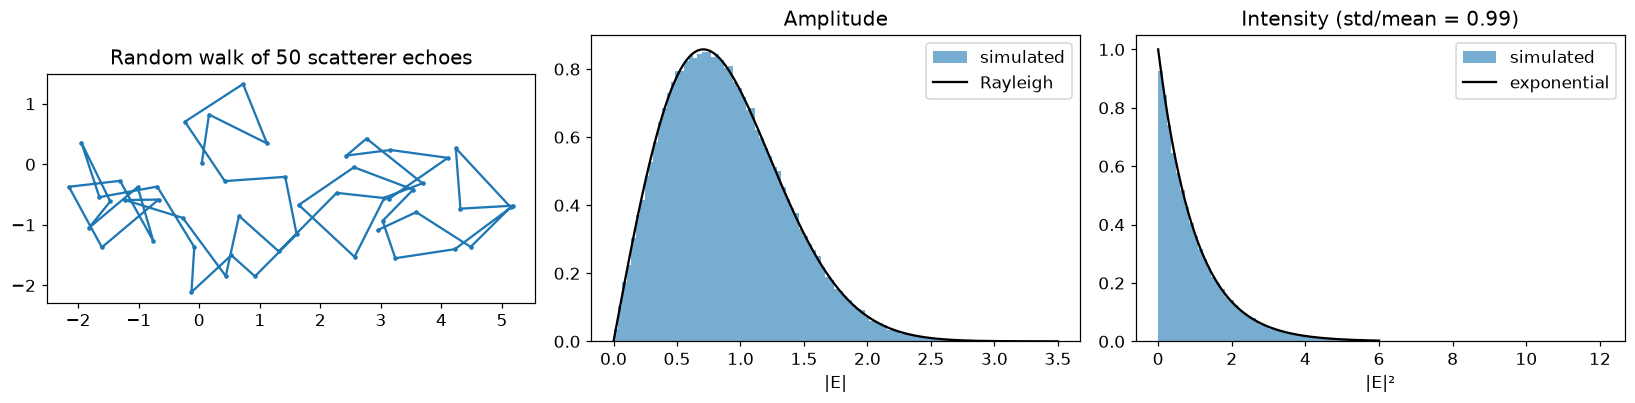

In [22]:
rng = np.random.default_rng(0)  # random generator with a fixed seed
N, pixels = 50, 200_000  # 50 scatterers per pixel, 200,000 pixels
# each pixel sums 50 echoes with random phase: fully developed speckle
field = (np.exp(1j * rng.uniform(0, 2 * np.pi, (pixels, N))) / np.sqrt(N)).sum(1)
amp, inten = np.abs(field), np.abs(field) ** 2  # amplitude and intensity of the summed field

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))  # three panels
# the running sum of one pixel's echoes in the complex plane (a random walk)
axes[0].plot(np.cumsum(np.exp(1j * rng.uniform(0, 2 * np.pi, N))).real,
             np.cumsum(np.exp(1j * rng.uniform(0, 2 * np.pi, N))).imag, "-o", ms=2)
axes[0].set(title=f"Random walk of {N} scatterer echoes", aspect="equal")  # title and equal axes
axes[1].hist(amp, 100, density=True, alpha=0.6, label="simulated")  # histogram of the simulated amplitude
# compare with the theoretical Rayleigh distribution
a = np.linspace(0, 3.5, 200); axes[1].plot(a, stats.rayleigh(scale=np.sqrt(0.5)).pdf(a), "k", label="Rayleigh")
axes[1].set(title="Amplitude", xlabel="|E|"); axes[1].legend()  # labels and legend
axes[2].hist(inten, 100, density=True, alpha=0.6, label="simulated")  # histogram of the simulated intensity
# compare with the theoretical exponential distribution
i = np.linspace(0, 6, 200); axes[2].plot(i, stats.expon().pdf(i), "k", label="exponential")
# the ratio std/mean is 1 for single-look intensity
axes[2].set(title=f"Intensity (std/mean = {inten.std() / inten.mean():.2f})", xlabel="|E|²"); axes[2].legend()
plt.tight_layout(); plt.show()  # arrange and draw

**Multilooking** averages *L* independent looks, reducing the relative standard deviation to
1/√L. The averaged intensity follows a Gamma distribution, and the **equivalent number of looks**
`ENL = mean² / variance` measured over a homogeneous area tells you how much speckle remains.


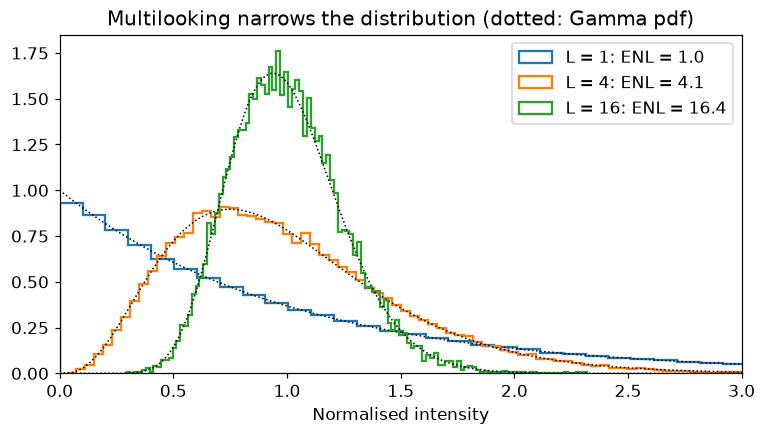

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))  # one panel
x = np.linspace(0, 3, 300)  # normalised intensity axis
for L in [1, 4, 16]:  # average 1, 4 and 16 independent looks
    # group the pixels in sets of L and average each set
    looks = inten[: pixels // L * L].reshape(-1, L).mean(1)
    # histogram with the estimated equivalent number of looks (ENL)
    ax.hist(looks, 120, density=True, histtype="step", lw=1.5, label=f"L = {L}: ENL = {rs.sar.enl_estimate(looks):.1f}")
    ax.plot(x, stats.gamma(L, scale=1 / L).pdf(x), "k:", lw=1)  # theoretical gamma distribution for L looks
# labels
ax.set(xlim=(0, 3), xlabel="Normalised intensity", title="Multilooking narrows the distribution (dotted: Gamma pdf)")
ax.legend(); plt.show()  # legend and draw

## Real Sentinel-1 backscatter

This real VV image (20 m, already terrain-corrected and in dB) comes from the pyroSAR test data.
SAR intensities span several orders of magnitude, so they are usually *displayed* in decibels,
`dB = 10·log10(σ⁰)`, but *averaged and filtered* in linear units: averaging dB values gives the
geometric mean and biases results low.


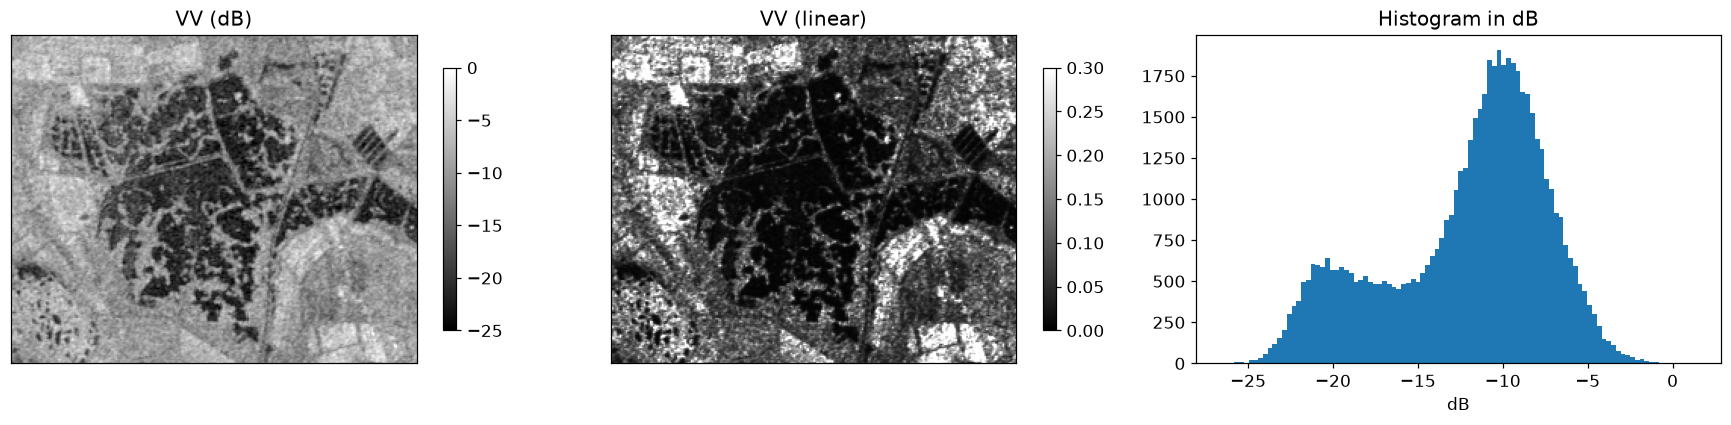

Mean of dB values: -12.12 dB | dB of the linear mean: -10.11 dB


In [24]:
# real Sentinel-1 VV backscatter in dB, as a 2-D DataArray
db = rs.read(fetch("s1_vv_db.tif")).squeeze("band", drop=True)
db = db.where(db > -60)  # mask no-data values
lin = rs.sar.from_db(db)  # dB -> linear power
fig, axes = plt.subplots(1, 3, figsize=(16, 4))  # three panels
rs.viz.plot_raster(db, ax=axes[0], cmap="gray", vmin=-25, vmax=0, title="VV (dB)")  # the image in dB
# the same image on a linear scale
rs.viz.plot_raster(lin, ax=axes[1], cmap="gray", vmin=0, vmax=0.3, title="VV (linear)")
# histogram of the dB values
axes[2].hist(db.values.ravel(), 100, color="C0"); axes[2].set(xlabel="dB", title="Histogram in dB")
for a in axes[:2]: a.set_xticks([]); a.set_yticks([])  # no ticks on the two images
plt.tight_layout(); plt.show()  # arrange and draw
# averaging in dB is not the same as averaging linear power
print(f"Mean of dB values: {float(db.mean()):.2f} dB | dB of the linear mean: {float(rs.sar.to_db(lin.mean())):.2f} dB")

In [25]:
# ENL in the most homogeneous 15 × 15 window (lowest coefficient of variation)
w = 15  # window size (pixels)
best = (np.inf, None)  # (lowest coefficient of variation, position) found so far
L = lin.values  # linear backscatter as an array
for r in range(0, L.shape[0] - w, 5):  # slide the window every 5 rows ...
    for c in range(0, L.shape[1] - w, 5):  # ... and every 5 columns
        blk = L[r:r + w, c:c + w]  # the 15 x 15 block
        if np.isnan(blk).any():  # skip blocks with missing values
            continue
        cv = blk.std() / blk.mean()  # coefficient of variation of the block
        if cv < best[0]:  # keep the most homogeneous block
            best = (cv, (r, c))  # keep its CV and position
r, c = best[1]  # its top-left corner
# ENL of that block
print(f"Most homogeneous window at row {r}, col {c}: ENL = {rs.sar.enl_estimate(L[r:r + w, c:c + w]):.1f}")
# for comparison
print("Nominal ENL of Sentinel-1 IW GRDH: 4.4 (this product was further multilooked and resampled to 20 m)")

Most homogeneous window at row 195, col 85: ENL = 11.6
Nominal ENL of Sentinel-1 IW GRDH: 4.4 (this product was further multilooked and resampled to 20 m)


## A simulated Sentinel-1 view of Long Valley

The simulator places a radar over the real terrain of Mono Lake, Long Valley caldera and the
Sierra Nevada crest. Compare the optical image with simulated VV and VH, and see where geometry
makes SAR unusable.


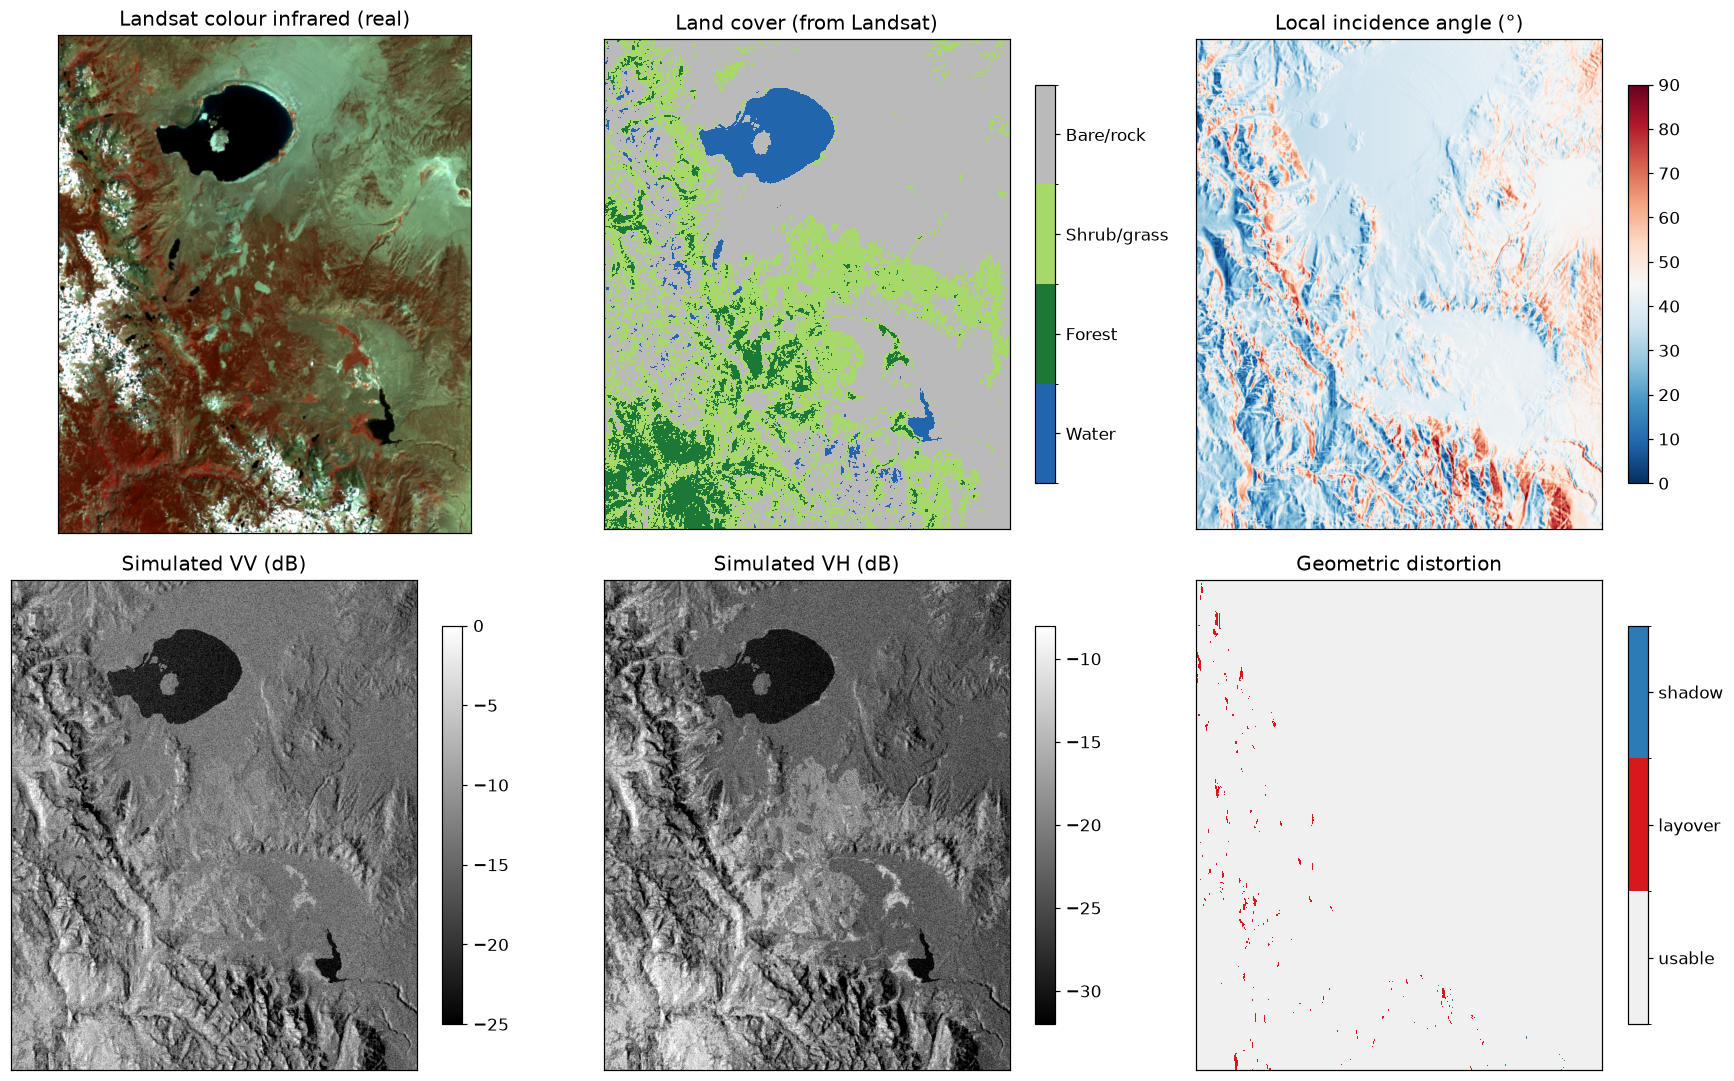

Layover: 0.41% of pixels, shadow: 0.01%


In [26]:
incidence = sim.incidence_grid(scene.elevation)                  # 30° (west) → 46° (east), looking east
# local incidence angle and layover and shadow masks from the DEM
local_inc, layover, shadow = sim.local_geometry(scene.elevation, incidence)
# simulated VV backscatter with speckle
vv = sim.speckle(sim.backscatter(scene.landcover, local_inc, "VV", incidence=incidence), seed=1)
# simulated VH backscatter with speckle
vh = sim.speckle(sim.backscatter(scene.landcover, local_inc, "VH", incidence=incidence), seed=2)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))  # 2 x 3 panels
# the real Landsat image in colour infrared
rs.viz.plot_rgb(optical, ["nir", "red", "green"], ax=axes[0, 0], title="Landsat colour infrared (real)")
# the land-cover classes the simulation uses
rs.viz.plot_raster(scene.landcover.where(scene.landcover > 0), ax=axes[0, 1], title="Land cover (from Landsat)",
                   categorical={1: ("Water", "#2166ac"), 2: ("Forest", "#1b7837"), 3: ("Shrub/grass", "#a6d96a"),
                                4: ("Bare/rock", "#bababa")})
# local incidence angle
rs.viz.plot_raster(local_inc, ax=axes[0, 2], cmap="RdBu_r", vmin=0, vmax=90, title="Local incidence angle (°)")
# simulated VV in dB
rs.viz.plot_raster(rs.sar.to_db(vv), ax=axes[1, 0], cmap="gray", vmin=-25, vmax=0, title="Simulated VV (dB)")
# simulated VH in dB
rs.viz.plot_raster(rs.sar.to_db(vh), ax=axes[1, 1], cmap="gray", vmin=-32, vmax=-8, title="Simulated VH (dB)")
# 0 = usable, 1 = layover, 2 = shadow
geo = (layover.astype(int) + 2 * shadow.astype(int)).where(scene.landcover > 0)
rs.viz.plot_raster(geo, ax=axes[1, 2], title="Geometric distortion",  # geometric distortion map
                   categorical={0: ("usable", "#f0f0f0"), 1: ("layover", "#d7191c"), 2: ("shadow", "#2c7bb6")})
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw
# share of layover and shadow pixels
print(f"Layover: {float(layover.mean()):.2%} of pixels, shadow: {float(shadow.mean()):.2%}")

Slopes facing the radar (west-facing) are bright and compressed; lakes are black; forest stands
out in VH because volume scattering depolarises the signal. Geometry, not land cover, dominates
the brightness in the mountains, which is why terrain correction (see the Sentinel-1 GRD notebook) comes first.


## Sentinel-1 acquisition modes and products


In [27]:
pd.DataFrame([  # Sentinel-1 acquisition modes as a table
    ("IW (Interferometric Wide)", "250 km", "5 × 20 m", "VV+VH (land), HH+HV (polar)", "Default over land"),
    ("EW (Extra Wide)", "400 km", "20 × 40 m", "HH+HV", "Sea ice, oceans"),
    ("SM (Stripmap)", "80 km", "5 × 5 m", "Dual", "Small islands, emergencies"),
    ("WV (Wave)", "20 × 20 km vignettes", "5 × 5 m", "Single", "Ocean waves"),
], columns=["Mode", "Swath", "Resolution", "Polarisation", "Use"])  # column names

,Mode,Swath,Resolution,Polarisation,Use
0,IW (Interferometric Wide),250 km,5 × 20 m,"VV+VH (land), HH+HV (polar)",Default over land
1,EW (Extra Wide),400 km,20 × 40 m,HH+HV,"Sea ice, oceans"
2,SM (Stripmap),80 km,5 × 5 m,Dual,"Small islands, emergencies"
3,WV (Wave),20 × 20 km vignettes,5 × 5 m,Single,Ocean waves


In [28]:
import xml.etree.ElementTree as ET  # XML parsing from the standard library

xml_path = fetch("s1_annotation.xml")  # download (once) the real annotation XML

# geolattice.rsense.sar.sentinel1's own annotation-XML readers, rather than hand-rolled ElementTree
# lookups: the sparse geolocationGridPointList (incidence angle, lat/lon, height) and the
# platform heading / pass direction -- see Section 3's local_incidence_angle, which needs
# exactly these two.
# the sparse geolocation grid: line and pixel positions and the values at each point
lines, pixels, grid = s1.read_geolocation_grid(xml_path)
# platform heading and pass direction (ascending or descending)
heading, pass_dir = s1.read_platform_heading(xml_path)
incs = grid["incidenceAngle"]  # incidence angle at every grid point

# A handful of scalar product fields sentinel1.py has no dedicated reader for (it focuses on
# what the processing chain needs: geometry and calibration, not every header field) -- read
# directly from the same annotation XML.
root = ET.parse(xml_path).getroot()  # root element of the XML document
info = {  # a few header fields, read directly from the XML
    "mission/product": "Sentinel-1B IW GRDH (real annotation)",
    "start time": root.find(".//adsHeader/startTime").text,  # acquisition start time
    "pass": pass_dir,
    "platform heading (°)": round(heading, 2),
    "radar frequency (GHz)": float(root.find(".//radarFrequency").text) / 1e9,  # radar frequency in GHz
    # wavelength = c / frequency, in cm
    "wavelength (cm)": round(299_792_458 / float(root.find(".//radarFrequency").text) * 100, 3),
    # pixel spacing
    "pixel spacing range × azimuth (m)": f"{root.find('.//rangePixelSpacing').text} × {root.find('.//azimuthPixelSpacing').text}",
    # image size
    "image size (lines × samples)": f"{root.find('.//numberOfLines').text} × {root.find('.//numberOfSamples').text}",
    # range of incidence angles across the swath
    "incidence angle range (°)": f"{np.nanmin(incs):.1f}: {np.nanmax(incs):.1f}",
    # size of the geolocation grid
    "geolocation grid": f"{lines.size} lines × {pixels.size} pixels (sparse control grid)",
}
pd.Series(info)  # show as a list

mission/product                           Sentinel-1B IW GRDH (real annotation)
start time                                           2021-12-23T05:11:22.594441
pass                                                                 Descending
platform heading (°)                                                     193.69
radar frequency (GHz)                                                     5.405
wavelength (cm)                                                           5.547
pixel spacing range × azimuth (m)                   1.000000e+01 × 1.000000e+01
image size (lines × samples)                                      16705 × 26102
incidence angle range (°)                                            30.3: 46.1
geolocation grid                     10 lines × 21 pixels (sparse control grid)
dtype: object

In [29]:
if RUN_ONLINE:  # only when the online example is switched on
    bbox = (-119.3, 37.45, -118.6, 38.15)   # same Long Valley / Mono Lake area as Section 7
    dates = ("2024-06-01", "2024-06-30")  # one month of acquisitions

    # Search first (free -- lists real scenes without downloading anything)
    # search the Planetary Computer catalogue for Sentinel-1 RTC scenes (no download)
    found = search_images(bbox=bbox, dates=dates, source="planetary",
                          collection="sentinel-1-rtc", s1_orbit="ascending")
    print(f"{len(found.scenes)} scene(s):", [sc["id"] for sc in found.scenes])  # the scene IDs that were found

    # Download the clearest scene's VV/VH, clipped to the AOI, the same workflow GeoLattice
    # Explorer's sidebar drives (geolattice.rsense.get_images)
    rtc_files = sorted(Path("../../../../Data/08_remote_sensing/08_03_radar/s1_rtc_long_valley").rglob("*.tif"))  # files of an earlier download
    if rtc_files:  # downloaded before: read them from the local drive
        print("Already on the local drive:", [str(p) for p in rtc_files])  # their paths
    else:  # not on disk yet
        # download VV and VH of the clearest scene, clipped to the box
        saved = get_images("../../../../Data/08_remote_sensing/08_03_radar/s1_rtc_long_valley", bbox=bbox, dates=dates, source="planetary",
                           collection="sentinel-1-rtc", s1_orbit="ascending",
                           bands=["vv", "vh"], mode="clip", clearest=True)  # only the requested bands, clipped
        print(saved.files)  # paths of the saved files

    # Or load straight into an in-memory Dataset without saving files first
    # or load the scenes directly into memory as an xarray Dataset
    s1_rtc = rs.sar.load_rtc(bbox, dates, orbit="ascending")
    print(s1_rtc)  # show the Dataset

## Summary, exercises and references

**Key points**

- Wavelength controls penetration and apparent roughness (Rayleigh criterion).
- SAR images are formed in slant range; terrain causes foreshortening, layover and shadow.
- Brightness reflects scattering mechanism, geometry and moisture; VH highlights volume scattering.
- Speckle is multiplicative; ENL measures it; filter and average in linear units, display in dB.
- `geolattice.rsense.sar` (`src/rsense/sar`) covers Sentinel-1, RCM and NISAR processing, speckle, polarimetry, change detection and applications.

**`geolattice.rsense` functions used:** `rs.read`, `rs.sar.to_db`/`from_db`, `rs.sar.enl_estimate`,
`rs.viz.plot_raster`, `rs.lidar.slope`/`aspect` (inside the simulator); `geolattice.rsense.sar.sentinel1`'s
`read_geolocation_grid`, `read_platform_heading` and `load_rtc`; `geolattice.rsense.get_images`'s
`search_images` and `get_images`.

**Exercises**

1. Recompute the profile in the *Imaging geometry* section for a radar looking *west* (descending). Which slopes now suffer layover?
2. Change the simulator's incidence range to 20-30° and compare layover and shadow fractions.
3. Estimate ENL in three homogeneous windows of the real image and explain any differences.
4. Using the Rayleigh criterion, at what wavelength would a 2 cm-rough field look smooth at 40°?
5. From the `src/rsense/sar` module table, name the submodule you would use for (a) refined Lee filtering, (b) RCM compact-pol m-χ, and (c) NISAR GCOV indices.
6. In the visual walkthrough, explain why calm open water is dark in SAR while flooded vegetation can be bright.
